Melinda Venta Lydia Siburian
(23031554124)

# SOAL UTS GRAF SAINS DATA

## **2.1 Wrangling dan EDA**

Menyiapkan library untuk membaca data, mengakses Neo4j melalui Python API, membangun matriks sparse, dan membuat visualisasi NetworkX.

In [1]:
%pip install pandas numpy scipy scikit-learn matplotlib networkx neo4j

  Using cached scipy-1.17.1-cp311-cp311-win_amd64.whl.metadata (60 kB)
  Using cached networkx-3.6.1-py3-none-any.whl.metadata (6.8 kB)
  Using cached contourpy-1.3.3-cp311-cp311-win_amd64.whl.metadata (5.5 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
Using cached scipy-1.17.1-cp311-cp311-win_amd64.whl (36.6 MB)
   ---------------------------------------- 0.0/8.3 MB ? eta -:--:--
   -- ------------------------------------- 0.5/8.3 MB 2.8 MB/s eta 0:00:03
   ----- ---------------------------------- 1.0/8.3 MB 2.6 MB/s eta 0:00:03
   ------- -------------------------------- 1.6/8.3 MB 2.7 MB/s eta 0:00:03
   ---------- ----------------------------- 2.1/8.3 MB 2.8 MB/s eta 0:00:03
   ----------- ---------------------------- 2.4/8.3 MB 2.7 MB/s eta 0:00:03
   ------------ --------------------------- 2.6/8.3 MB 2.3 MB/s eta 0:00:03
   ------------- -------------------------- 2.9/8.3 MB 2.2 MB/s eta 0:

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

from scipy.sparse import csr_matrix, save_npz
from sklearn.preprocessing import normalize
from neo4j import GraphDatabase
from getpass import getpass

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 150)

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

OUTPUT_DIR = "/content/hasil_analisis"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Folder output:", OUTPUT_DIR)

Folder output: /content/hasil_analisis


### no.1 dan 2 : Split Dataset berdasarkan timestamp

In [4]:
# GANTI sesuai lokasi events.csv milikmu
DATA_PATH = r"C:\Users\Melinda Siburian\OneDrive\Documents\uts_gsd\data\archive (4)\events.csv"

P1_START = "2015-05-16"
P1_END   = "2015-08-04"

P2_START = "2015-08-05"
P2_END   = "2015-08-25"

# Batas akhir eksklusif: awal hari setelah tanggal akhir
P1_START_TS = pd.Timestamp(P1_START, tz="UTC")
P1_END_EXCLUSIVE = pd.Timestamp(P1_END, tz="UTC") + pd.Timedelta(days=1)

P2_START_TS = pd.Timestamp(P2_START, tz="UTC")
P2_END_EXCLUSIVE = pd.Timestamp(P2_END, tz="UTC") + pd.Timedelta(days=1)

print("P1:", P1_START_TS, "sampai sebelum", P1_END_EXCLUSIVE)
print("P2:", P2_START_TS, "sampai sebelum", P2_END_EXCLUSIVE)

assert os.path.exists(DATA_PATH), (
    f"File tidak ditemukan: {DATA_PATH}. "
    "Silakan ubah DATA_PATH sesuai lokasi events.csv."
)

P1: 2015-05-16 00:00:00+00:00 sampai sebelum 2015-08-05 00:00:00+00:00
P2: 2015-08-05 00:00:00+00:00 sampai sebelum 2015-08-26 00:00:00+00:00


**Membaca dan memeriksa dataset**

memeriksa nama kolom, tipe data, jumlah baris, dan distribusi event.


In [5]:
df = pd.read_csv(DATA_PATH)

required_columns = {
    "timestamp", "visitorid", "event", "itemid"
}
missing_columns = required_columns - set(df.columns)

if missing_columns:
    raise ValueError(f"Kolom wajib tidak ditemukan: {missing_columns}")

# Timestamp RetailRocket merupakan Unix time dalam milidetik
df["timestamp"] = pd.to_numeric(df["timestamp"], errors="coerce")
df = df.dropna(
    subset=["timestamp", "visitorid", "event", "itemid"]
).copy()

df["timestamp"] = df["timestamp"].astype("int64")

# Identitas diseragamkan sebagai string agar aman saat diimpor ke Neo4j
df["visitorid"] = df["visitorid"].astype(str)
df["itemid"] = df["itemid"].astype(str)
df["event"] = df["event"].astype(str)

df["event_datetime"] = pd.to_datetime(
    df["timestamp"], unit="ms", utc=True
)

print("Jumlah interaksi setelah membersihkan kolom wajib:", len(df))
print("\nContoh data:")
display(df.head())

print("\nDistribusi event:")
display(df["event"].value_counts().rename_axis("event").to_frame("jumlah"))

Jumlah interaksi setelah membersihkan kolom wajib: 2756101

Contoh data:


,timestamp,visitorid,event,itemid,transactionid,event_datetime
0,1433221332117,257597,view,355908,NaN,2015-06-02 05:02:12.117000+00:00
1,1433224214164,992329,view,248676,NaN,2015-06-02 05:50:14.164000+00:00
2,1433221999827,111016,view,318965,NaN,2015-06-02 05:13:19.827000+00:00
3,1433221955914,483717,view,253185,NaN,2015-06-02 05:12:35.914000+00:00
4,1433221337106,951259,view,367447,NaN,2015-06-02 05:02:17.106000+00:00



Distribusi event:


,jumlah
event,
view,2664312
addtocart,69332
transaction,22457


**Pembagian P1 dan P2 dan disimpan di CSV**


In [6]:
mask_p1 = (
    (df["event_datetime"] >= P1_START_TS) &
    (df["event_datetime"] < P1_END_EXCLUSIVE)
)

mask_p2 = (
    (df["event_datetime"] >= P2_START_TS) &
    (df["event_datetime"] < P2_END_EXCLUSIVE)
)

p1 = df.loc[mask_p1].copy()
p2 = df.loc[mask_p2].copy()

p1["period"] = "P1"
p2["period"] = "P2"

# Simpan kolom inti; timestamp asli tetap dipertahankan
CSV_COLUMNS = [
    "timestamp", "visitorid", "event", "itemid", "period"
]

p1_csv = os.path.join(OUTPUT_DIR, "retailrocket_P1_training.csv")
p2_csv = os.path.join(OUTPUT_DIR, "retailrocket_P2_testing.csv")
all_csv = os.path.join(OUTPUT_DIR, "retailrocket_P1_P2_filtered.csv")

p1[CSV_COLUMNS].to_csv(p1_csv, index=False)
p2[CSV_COLUMNS].to_csv(p2_csv, index=False)
pd.concat([p1[CSV_COLUMNS], p2[CSV_COLUMNS]], ignore_index=True).to_csv(
    all_csv, index=False
)

print("Jumlah interaksi P1:", len(p1))
print("Jumlah interaksi P2:", len(p2))
print("CSV P1:", p1_csv)
print("CSV P2:", p2_csv)
print("CSV gabungan:", all_csv)

assert len(p1) > 0, "P1 kosong. Periksa timestamp dan periode."
assert len(p2) > 0, "P2 kosong. Periksa timestamp dan periode."

Jumlah interaksi P1: 1716085
Jumlah interaksi P2: 372163
CSV P1: /content/hasil_analisis\retailrocket_P1_training.csv
CSV P2: /content/hasil_analisis\retailrocket_P2_testing.csv
CSV gabungan: /content/hasil_analisis\retailrocket_P1_P2_filtered.csv


**Komposisi periode dan event setelah filter**

In [7]:
print("Interaksi per periode:")
display(
    pd.concat([p1, p2])
    .groupby("period")
    .agg(
        jumlah_interaksi=("itemid", "size"),
        jumlah_user=("visitorid", "nunique"),
        jumlah_item=("itemid", "nunique")
    )
)

print("\nEvent per periode:")
display(
    pd.concat([p1, p2])
    .groupby(["period", "event"])
    .size()
    .unstack(fill_value=0)
)

Interaksi per periode:


,jumlah_interaksi,jumlah_user,jumlah_item
period,,,
P1,1716085,879515,191638
P2,372163,212596,92531



Event per periode:


event,addtocart,transaction,view
period,,,
P1,42210,13942,1659933
P2,9891,3076,359196


### No. 3: Komposisi subgraph (Cypher + Python API)

**Konfigurasi koneksi Neo4j**

In [11]:
from neo4j import GraphDatabase
from getpass import getpass

URI = "neo4j://127.0.0.1:7687"
USERNAME = "neo4j"
PASSWORD = getpass("Masukkan password Neo4j: ")

# Gunakan "neo4j" jika memakai database default.
DATABASE = "neo4j"

driver = None

try:
    driver = GraphDatabase.driver(
        URI,
        auth=(USERNAME, PASSWORD)
    )

    driver.verify_connectivity()
    print("Koneksi ke Neo4j berhasil!")

    with driver.session(database=DATABASE) as session:
        result = session.run(
            "RETURN 'Koneksi berhasil' AS status"
        )
        record = result.single()
        print(record["status"])

except Exception as e:
    print("Koneksi gagal:", e)

finally:
    if driver is not None:
        driver.close()


Koneksi ke Neo4j berhasil!
Koneksi berhasil


In [13]:

from neo4j import GraphDatabase
from getpass import getpass

URI = "neo4j://127.0.0.1:7687"
USERNAME = "neo4j"
DATABASE = "neo4j"

PASSWORD = getpass("Masukkan password Neo4j: ")

# Buat driver baru
driver = GraphDatabase.driver(
    URI,
    auth=(USERNAME, PASSWORD)
)

# Pastikan koneksi aktif
driver.verify_connectivity()

print("Koneksi Neo4j berhasil dan driver aktif!")


Koneksi Neo4j berhasil dan driver aktif!


**Membuat skema graf dan constraint**

Dibuat dua label node, yaitu Visitor dan Item, serta relasi INTERACTED. visitorId dan itemId menjadi identitas unik masing-masing node. Setiap baris interaksi akan menjadi satu relasi yang menyimpan event, timestamp, dan period.

In [14]:
SCHEMA_QUERIES = [
    """
    CREATE CONSTRAINT visitor_id_unique IF NOT EXISTS
    FOR (v:Visitor)
    REQUIRE v.visitorId IS UNIQUE
    """,
    """
    CREATE CONSTRAINT item_id_unique IF NOT EXISTS
    FOR (i:Item)
    REQUIRE i.itemId IS UNIQUE
    """
]

with driver.session() as session:
    for query in SCHEMA_QUERIES:
        session.run(query).consume()

print("Constraint Visitor dan Item berhasil disiapkan.")

Constraint Visitor dan Item berhasil disiapkan.


**Mengimpor data P1 dan P2 ke Neo4j**

Query Cypher menggunakan UNWIND untuk memasukkan data per batch. MERGE menjaga satu node untuk setiap ID, sementara CREATE mempertahankan setiap baris interaksi sebagai relasi. Kita impor P1 dan P2 agar keduanya tersedia di database; analisis VSM utama nanti menggunakan P1 saja.

In [15]:
IMPORT_QUERY = """
UNWIND $rows AS row

MERGE (v:Visitor {visitorId: row.visitorid})
MERGE (i:Item {itemId: row.itemid})

CREATE (v)-[:INTERACTED {
    event: row.event,
    timestamp: row.timestamp,
    period: row.period
}]->(i)

RETURN count(*) AS imported
"""

def import_interactions_to_neo4j(dataframe, batch_size=5000):
    records = dataframe[
        ["timestamp", "visitorid", "event", "itemid", "period"]
    ].to_dict("records")

    total = len(records)

    with driver.session() as session:
        for start in range(0, total, batch_size):
            batch = records[start:start + batch_size]
            result = session.run(IMPORT_QUERY, rows=batch)
            imported = result.single()["imported"]

            print(
                f"Diimpor {min(start + len(batch), total):,}"
                f" / {total:,} baris; batch ini: {imported:,}"
            )

# Impor data filter P1 dan P2
filtered_data = pd.concat([p1, p2], ignore_index=True)

import_interactions_to_neo4j(filtered_data, batch_size=5000)

Diimpor 5,000 / 2,088,248 baris; batch ini: 5,000
Diimpor 10,000 / 2,088,248 baris; batch ini: 5,000
Diimpor 15,000 / 2,088,248 baris; batch ini: 5,000
Diimpor 20,000 / 2,088,248 baris; batch ini: 5,000
Diimpor 25,000 / 2,088,248 baris; batch ini: 5,000
Diimpor 30,000 / 2,088,248 baris; batch ini: 5,000
Diimpor 35,000 / 2,088,248 baris; batch ini: 5,000
Diimpor 40,000 / 2,088,248 baris; batch ini: 5,000
Diimpor 45,000 / 2,088,248 baris; batch ini: 5,000
Diimpor 50,000 / 2,088,248 baris; batch ini: 5,000
Diimpor 55,000 / 2,088,248 baris; batch ini: 5,000
Diimpor 60,000 / 2,088,248 baris; batch ini: 5,000
Diimpor 65,000 / 2,088,248 baris; batch ini: 5,000
Diimpor 70,000 / 2,088,248 baris; batch ini: 5,000
Diimpor 75,000 / 2,088,248 baris; batch ini: 5,000
Diimpor 80,000 / 2,088,248 baris; batch ini: 5,000
Diimpor 85,000 / 2,088,248 baris; batch ini: 5,000
Diimpor 90,000 / 2,088,248 baris; batch ini: 5,000
Diimpor 95,000 / 2,088,248 baris; batch ini: 5,000
Diimpor 100,000 / 2,088,248 bari

**Menjalankan Cypher untuk mengetahui komposisi subgraph**


**1. Query untuk menghitung jumlah node berdasarkan label**

Penjelasan Cypher:
- MATCH (n) mengambil seluruh node dalam database.
- labels(n) memperoleh label dari setiap node.
- UNWIND mengubah daftar label menjadi baris terpisah.
- count(*) menghitung jumlah node untuk setiap label.
Karena query ini menghitung node di seluruh database, hasilnya mencakup node yang berinteraksi pada P1 maupun P2.

In [16]:
QUERY_NODE_COMPOSITION = """
MATCH (n)
UNWIND labels(n) AS label
RETURN label, count(*) AS jumlah_node
ORDER BY label
"""

with driver.session() as session:
    node_composition = pd.DataFrame(
        [record.data() for record in session.run(QUERY_NODE_COMPOSITION)]
    )

display(node_composition)

,label,jumlah_node
0,Item,408719
1,Visitor,2037688


**2. Query untuk komposisi subgraph P1**

Penjelasan Cypher:
- MATCH memilih relasi interaksi dari Visitor ke Item.
- {period: 'P1'} membatasi analisis pada relasi training.
- count(r) menghitung semua relasi interaksi, termasuk relasi berulang antara pasangan user-item.
- count(DISTINCT v) dan count(DISTINCT i) menghitung user dan item unik yang terlibat dalam P1.

In [17]:
QUERY_P1_COMPOSITION = """
MATCH (v:Visitor)-[r:INTERACTED {period: 'P1'}]->(i:Item)
RETURN
    count(r) AS jumlah_relasi,
    count(DISTINCT v) AS jumlah_visitor,
    count(DISTINCT i) AS jumlah_item,
    count(DISTINCT v) + count(DISTINCT i) AS jumlah_node_terlibat
"""

with driver.session() as session:
    p1_composition = session.run(
        QUERY_P1_COMPOSITION
    ).single().data()

display(pd.DataFrame([p1_composition]))

,jumlah_relasi,jumlah_visitor,jumlah_item,jumlah_node_terlibat
0,1716085,879515,191638,1071153


Terdapat 1.716.085 relasi interaksi, yang menunjukkan jumlah hubungan aktivitas pengunjung dengan produk, serta 879.515 visitor dan 191.638 item.

Sementara itu, jumlah node terlibat sebanyak 1.071.153 berarti jumlah pengunjung dan produk unik yang benar-benar memiliki hubungan interaksi dalam graph training. Sebagai contoh, pengunjung yang melihat suatu produk akan membentuk hubungan antara node visitor dan node item. Jika ada pengunjung atau produk yang tidak memiliki interaksi selama periode training, node tersebut tidak dihitung sebagai node yang terlibat. Jadi, jumlah node terlibat menunjukkan berapa banyak pengunjung dan produk yang benar-benar berpartisipasi dalam aktivitas pada graph training.

**3. Query untuk menghitung jenis event dalam subgraph P1**

In [18]:
QUERY_P1_EVENT_COMPOSITION = """
MATCH (:Visitor)-[r:INTERACTED {period: 'P1'}]->(:Item)
RETURN r.event AS event, count(r) AS jumlah_interaksi
ORDER BY jumlah_interaksi DESC
"""

with driver.session() as session:
    event_composition = pd.DataFrame(
        [record.data() for record in session.run(
            QUERY_P1_EVENT_COMPOSITION
        )]
    )

display(event_composition)

,event,jumlah_interaksi
0,view,1659933
1,addtocart,42210
2,transaction,13942


**Jawaban no 3**. Subgraph yang dibentuk terdiri atas dua jenis node, yaitu Item sebanyak 408.719 node dan Visitor sebanyak 2.037.688 node, yang merepresentasikan produk dan pengunjung dalam dataset. Berdasarkan ringkasan relasi, terdapat 1.716.085 pengunjung dan 879.515 item, dengan 1.071.153 node terlibat dalam relasi serta 191.638 item unik yang tercatat pada struktur interaksi. Interaksi yang membentuk subgraph terdiri atas tiga jenis, yaitu view sebanyak 1.659.933 interaksi, addtocart sebanyak 42.210 interaksi, dan transaction sebanyak 13.942 interaksi. Interaksi didominasi oleh aktivitas melihat produk (view), sedangkan aktivitas menambahkan produk ke keranjang dan transaksi memiliki jumlah yang jauh lebih sedikit. Komposisi ini menunjukkan bahwa subgraph lebih banyak merepresentasikan ketertarikan awal pengunjung terhadap produk daripada tindakan pembelian, sehingga pola interaksi tersebut dapat dimanfaatkan untuk membangun analisis hubungan pengguna dan item dalam sistem rekomendasi.

### No.4 : Membentuk VSM User dari P1


Pada VSM User, setiap baris mewakili satu Visitor, sedangkan setiap kolom mewakili satu Item. Nilai matriks adalah akumulasi bobot event untuk pasangan user-item. Karena satu user dapat melakukan beberapa jenis interaksi dengan item yang sama, bobotnya dijumlahkan.

dengan bobot view = 1, addtocart = 3, dan transaction = 5. Pemberian bobot view = 1, addtocart = 3, dan transaction = 5 bertujuan untuk membedakan tingkat ketertarikan pengguna terhadap suatu produk. Aktivitas view diberi bobot 1 karena hanya menunjukkan bahwa pengguna melihat produk, sedangkan addtocart diberi bobot 3 karena menunjukkan minat yang lebih besar melalui tindakan memasukkan produk ke keranjang. Sementara itu, transaction diberi bobot 5 karena menunjukkan tindakan pembelian yang merepresentasikan minat paling kuat. Pemilihan bobot ini didasarkan pada asumsi bahwa semakin jauh tindakan pengguna menuju pembelian, semakin tinggi nilai preferensinya terhadap produk tersebut.

Hasil VSM User kemudian disimpan dalam format sparse matrix CSR (Compressed Sparse Row), yaitu format penyimpanan matriks yang hanya menyimpan elemen bernilai bukan nol beserta informasi posisi baris dan kolomnya, tanpa menyimpan seluruh elemen nol. Format ini digunakan karena data interaksi pengguna dan item sangat jarang (sparse): sebagian besar pengguna hanya berinteraksi dengan sebagian kecil dari total item yang tersedia. Dengan CSR, penggunaan memori menjadi lebih efisien dan operasi komputasi, seperti perhitungan cosine similarity, dapat dilakukan dengan lebih praktis pada dataset berukuran besar.

In [19]:
EVENT_WEIGHTS = {
    "view": 1,
    "addtocart": 3,
    "transaction": 5
}

# Salin P1 untuk proses VSM
vsm_data = p1.copy()

vsm_data["weight"] = vsm_data["event"].map(EVENT_WEIGHTS)

# Periksa event yang tidak memiliki bobot
unknown_events = sorted(
    vsm_data.loc[vsm_data["weight"].isna(), "event"].unique()
)
print("Event yang tidak memiliki bobot:", unknown_events)

# Hanya event yang didefinisikan dalam skema pembobotan
vsm_data = vsm_data.dropna(subset=["weight"]).copy()
vsm_data["weight"] = vsm_data["weight"].astype(float)

# Akumulasi bobot per pasangan user-item
user_item_agg = (
    vsm_data.groupby(["visitorid", "itemid"], as_index=False)["weight"]
    .sum()
)

# Indeks baris dan kolom
user_ids = sorted(user_item_agg["visitorid"].unique())
item_ids = sorted(user_item_agg["itemid"].unique())

user_to_idx = {uid: idx for idx, uid in enumerate(user_ids)}
item_to_idx = {iid: idx for idx, iid in enumerate(item_ids)}

row_idx = user_item_agg["visitorid"].map(user_to_idx).to_numpy()
col_idx = user_item_agg["itemid"].map(item_to_idx).to_numpy()
values = user_item_agg["weight"].to_numpy(dtype=np.float32)

# Matriks VSM User: baris=user, kolom=item
X_user = csr_matrix(
    (values, (row_idx, col_idx)),
    shape=(len(user_ids), len(item_ids)),
    dtype=np.float32
)

print("Jumlah user:", len(user_ids))
print("Jumlah item:", len(item_ids))
print("Shape VSM User:", X_user.shape)
print("Jumlah nilai non-zero:", X_user.nnz)
print("Total elemen matriks:", X_user.shape[0] * X_user.shape[1])
print("Sparsity:", 1 - X_user.nnz / (X_user.shape[0] * X_user.shape[1]))

Event yang tidak memiliki bobot: []
Jumlah user: 879515
Jumlah item: 191638
Shape VSM User: (879515, 191638)
Jumlah nilai non-zero: 1334471
Total elemen matriks: 168548495570
Sparsity: 0.9999920825694973


**Menyimpan VSM USER**

In [20]:
save_npz(
    os.path.join(OUTPUT_DIR, "vsm_user_P1.npz"),
    X_user
)

pd.DataFrame({"visitorid": user_ids}).to_csv(
    os.path.join(OUTPUT_DIR, "vsm_user_row_ids.csv"),
    index=False
)

pd.DataFrame({"itemid": item_ids}).to_csv(
    os.path.join(OUTPUT_DIR, "vsm_user_column_ids.csv"),
    index=False
)

user_item_agg.to_csv(
    os.path.join(OUTPUT_DIR, "vsm_user_weighted_interactions.csv"),
    index=False
)

print("VSM User dan metadata ID berhasil disimpan.")

VSM User dan metadata ID berhasil disimpan.


**Menganalisis karakteristik VSM User**

Shape menunjukkan jumlah baris dan kolom. Dimensi matriks adalah dua, sedangkan ukuran setiap sumbu menunjukkan jumlah user dan item. Kita juga melihat distribusi jumlah item yang pernah diakses setiap user.

In [22]:
import numpy as np
import pandas as pd
from scipy.sparse import csr_matrix, issparse

# ============================================================
# KARAKTERISTIK VECTOR SPACE MODEL (VSM USER)
# ============================================================

# Pastikan matriks menggunakan format CSR
if not issparse(X_user):
    X_user = csr_matrix(X_user)
else:
    X_user = X_user.tocsr()

# Dimensi matriks
n_users, n_items = X_user.shape

# Jumlah elemen non-zero
nnz = X_user.nnz

# Total elemen matriks
total_elements = n_users * n_items

# Density dan sparsity
density = (nnz / total_elements * 100) if total_elements > 0 else 0
sparsity = 100 - density if total_elements > 0 else 0

# Jumlah NNZ untuk setiap vektor user
nnz_per_vector = np.diff(X_user.indptr)

# Statistik NNZ per vektor
mean_nnz = np.mean(nnz_per_vector) if n_users > 0 else 0
median_nnz = np.median(nnz_per_vector) if n_users > 0 else 0
max_nnz = np.max(nnz_per_vector) if n_users > 0 else 0

# Memori CSR: data + indeks kolom + pointer baris
memory_bytes = (
    X_user.data.nbytes
    + X_user.indices.nbytes
    + X_user.indptr.nbytes
)
memory_mb = memory_bytes / (1024 ** 2)

# ============================================================
# TABEL KARAKTERISTIK VSM USER
# ============================================================

vsm_user_characteristics = pd.DataFrame({
    "Karakteristik": [
        "shape",
        "jumlah vektor",
        "dimensi vektor",
        "nnz",
        "density",
        "sparsity (%)",
        "rata2 nnz/vektor",
        "median nnz/vektor",
        "maks nnz/vektor",
        "memori CSR (MB)"
    ],
    "VSM": [
        str(X_user.shape),
        f"{n_users:,}",
        f"{n_items:,}",
        f"{nnz:,}",
        f"{density:.6f}%",
        f"{sparsity:.6f}",
        f"{mean_nnz:.2f}",
        f"{median_nnz:.2f}",
        f"{max_nnz:,}",
        f"{memory_mb:.2f}"
    ]
})

display(
    vsm_user_characteristics.set_index("Karakteristik")
)

,VSM
Karakteristik,
shape,"(879515, 191638)"
jumlah vektor,"879,515"
dimensi vektor,"191,638"
nnz,"1,334,471"
density,0.000792%
sparsity (%),99.999208
rata2 nnz/vektor,1.52
median nnz/vektor,1.00
maks nnz/vektor,"2,721"


Visualisasi jumlah item unik yang diinteraksikan oleh user:

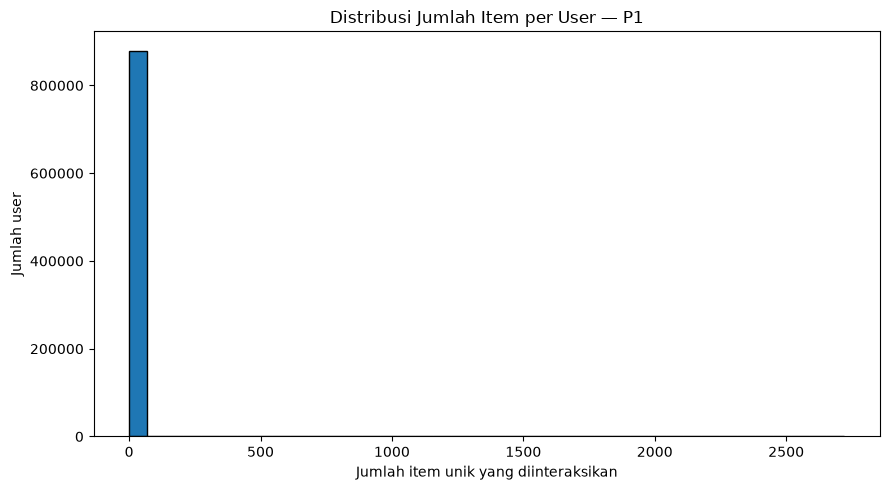

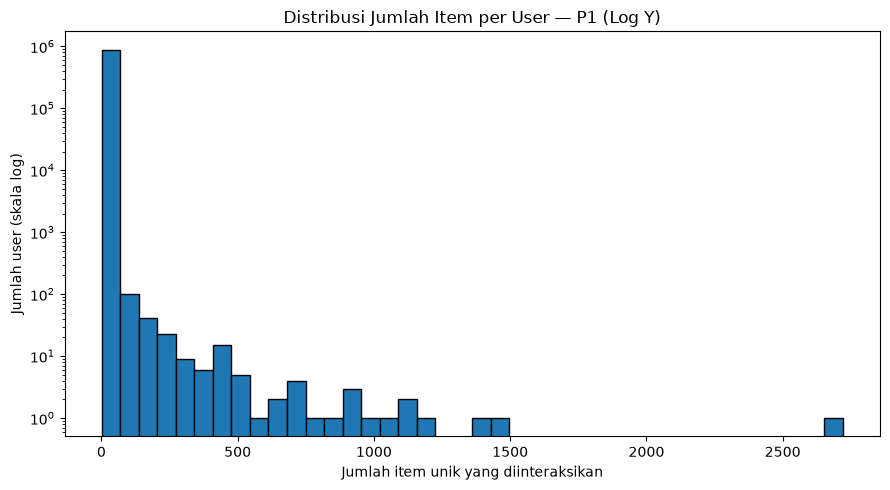

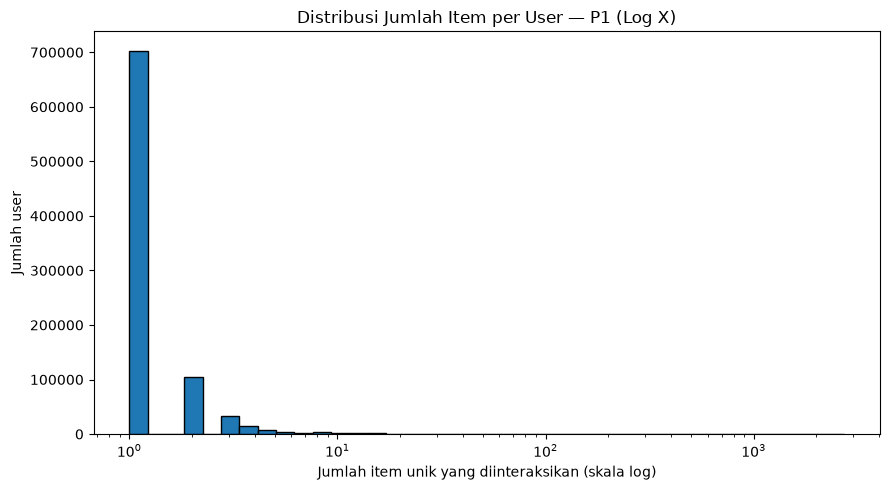

In [86]:
import matplotlib.pyplot as plt
import numpy as np

# Menghindari nilai 0 atau negatif untuk skala log X
jumlah_item = user_activity["jumlah_item"]
jumlah_item_positif = jumlah_item[jumlah_item > 0]

# ============================================================
# 1. HISTOGRAM BIASA
# ============================================================
plt.figure(figsize=(9, 5))
plt.hist(jumlah_item, bins=40, edgecolor="black")
plt.title("Distribusi Jumlah Item per User — P1")
plt.xlabel("Jumlah item unik yang diinteraksikan")
plt.ylabel("Jumlah user")
plt.tight_layout()
plt.show()

# ============================================================
# 2. HISTOGRAM DENGAN SKALA LOGARITMIK PADA SUMBU Y
# ============================================================
plt.figure(figsize=(9, 5))
plt.hist(jumlah_item, bins=40, edgecolor="black")
plt.yscale("log")
plt.title("Distribusi Jumlah Item per User — P1 (Log Y)")
plt.xlabel("Jumlah item unik yang diinteraksikan")
plt.ylabel("Jumlah user (skala log)")
plt.tight_layout()
plt.show()

# ============================================================
# 3. HISTOGRAM DENGAN SKALA LOGARITMIK PADA SUMBU X
# ============================================================
plt.figure(figsize=(9, 5))
plt.hist(jumlah_item_positif, bins=np.logspace(
    np.log10(jumlah_item_positif.min()),
    np.log10(jumlah_item_positif.max()),
    40
), edgecolor="black")
plt.xscale("log")
plt.title("Distribusi Jumlah Item per User — P1 (Log X)")
plt.xlabel("Jumlah item unik yang diinteraksikan (skala log)")
plt.ylabel("Jumlah user")
plt.tight_layout()
plt.show()

**Plot graf bipartit menggunakan NetworkX**

VSM adalah matriks, sedangkan NetworkX digunakan untuk menampilkan hubungan user-item sebagai graf bipartit. Node dari kedua kelompok dibuat berbeda. Agar visualisasi terbaca dan tidak terlalu berat, kita pilih paling banyak 20 user dan 20 item dengan bobot interaksi tertinggi. Ini adalah subgraf visualisasi, bukan keseluruhan graf.

In [25]:
# Derajat berbobot per user dan item
user_strength = user_item_agg.groupby("visitorid")["weight"].sum()
item_strength = user_item_agg.groupby("itemid")["weight"].sum()

top_users = user_strength.nlargest(min(20, len(user_strength))).index
top_items = item_strength.nlargest(min(20, len(item_strength))).index

plot_edges = user_item_agg[
    user_item_agg["visitorid"].isin(top_users) &
    user_item_agg["itemid"].isin(top_items)
].copy()

G = nx.Graph()

for uid in top_users:
    G.add_node(f"U_{uid}", bipartite="user", node_type="user")

for iid in top_items:
    G.add_node(f"I_{iid}", bipartite="item", node_type="item")

for row in plot_edges.itertuples(index=False):
    G.add_edge(
        f"U_{row.visitorid}",
        f"I_{row.itemid}",
        weight=float(row.weight)
    )

print("Jumlah node pada graf visualisasi:", G.number_of_nodes())
print("Jumlah edge pada graf visualisasi:", G.number_of_edges())

Jumlah node pada graf visualisasi: 40
Jumlah edge pada graf visualisasi: 145


Interpretasi: node Visitor dan Item berada pada dua kelompok berbeda. Edge menghubungkan user dengan item yang pernah diinteraksikan, dan ketebalan edge menggambarkan bobot interaksi agregat.

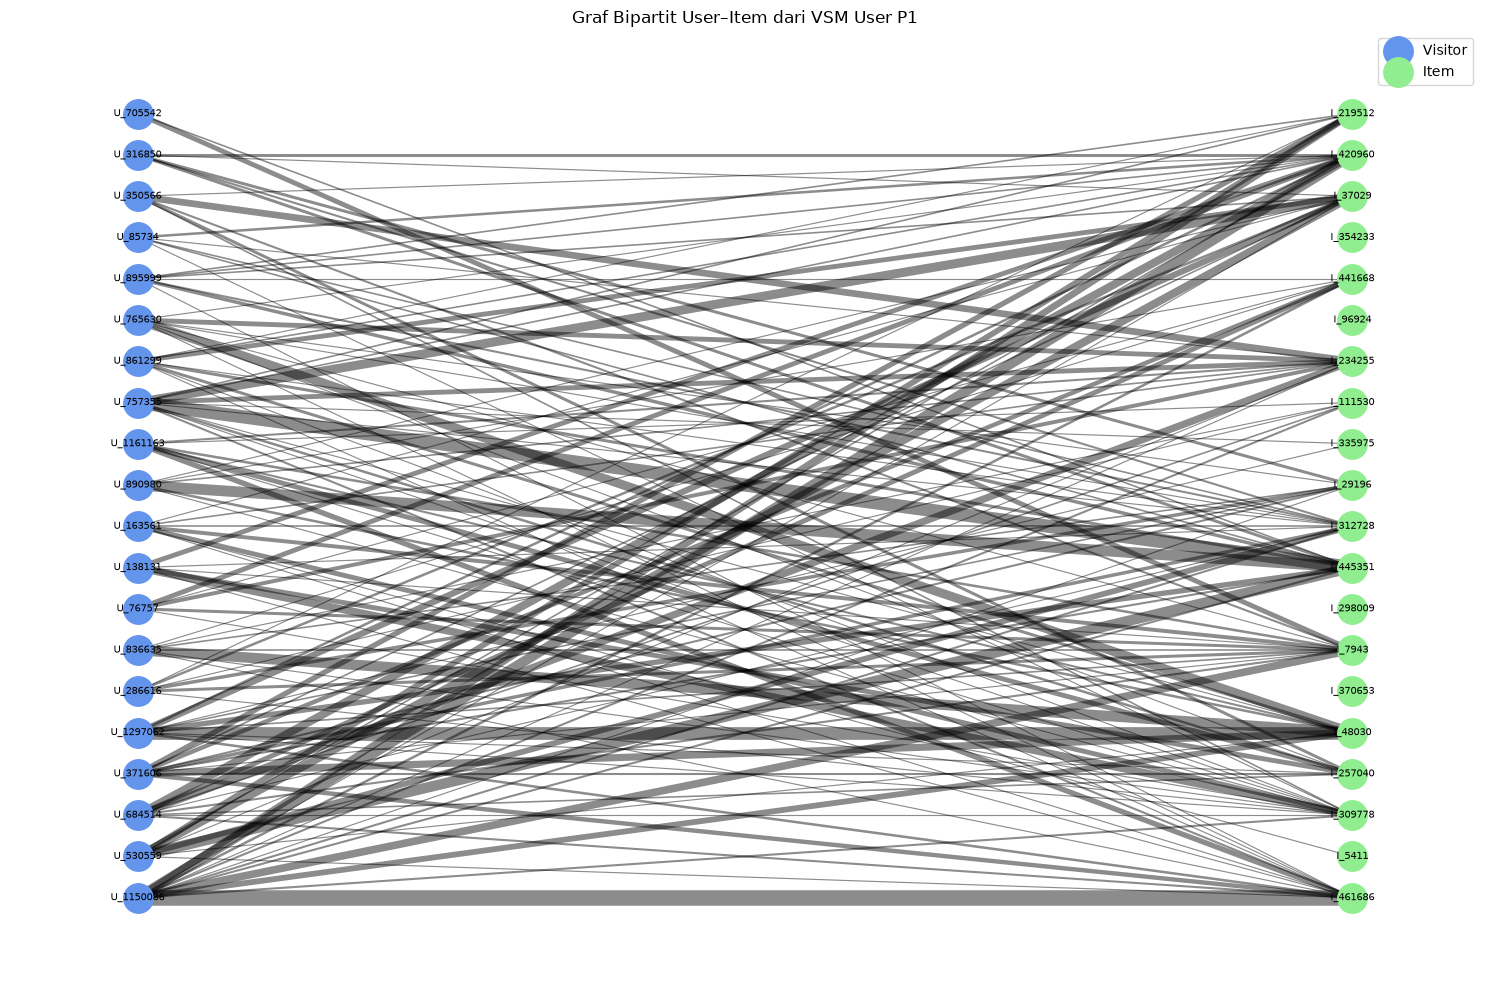

In [26]:
user_nodes = [
    n for n, d in G.nodes(data=True) if d["node_type"] == "user"
]
item_nodes = [
    n for n, d in G.nodes(data=True) if d["node_type"] == "item"
]

pos = {}

for idx, node in enumerate(user_nodes):
    pos[node] = (0, idx)

for idx, node in enumerate(item_nodes):
    pos[node] = (1, idx)

plt.figure(figsize=(15, 10))

nx.draw_networkx_nodes(
    G, pos,
    nodelist=user_nodes,
    node_color="cornflowerblue",
    node_size=450,
    label="Visitor"
)

nx.draw_networkx_nodes(
    G, pos,
    nodelist=item_nodes,
    node_color="lightgreen",
    node_size=450,
    label="Item"
)

nx.draw_networkx_edges(
    G, pos,
    width=[
        0.5 + G[u][v]["weight"] / 3
        for u, v in G.edges()
    ],
    alpha=0.45
)

nx.draw_networkx_labels(G, pos, font_size=7)

plt.title("Graf Bipartit User–Item dari VSM User P1")
plt.legend()
plt.axis("off")
plt.tight_layout()
plt.show()

mengambil 60 user dengan jumlah interaksi terbanyak agar graf mudah divisualisasikan. Setiap pasangan user yang memiliki minimal satu item bersama akan dihubungkan.

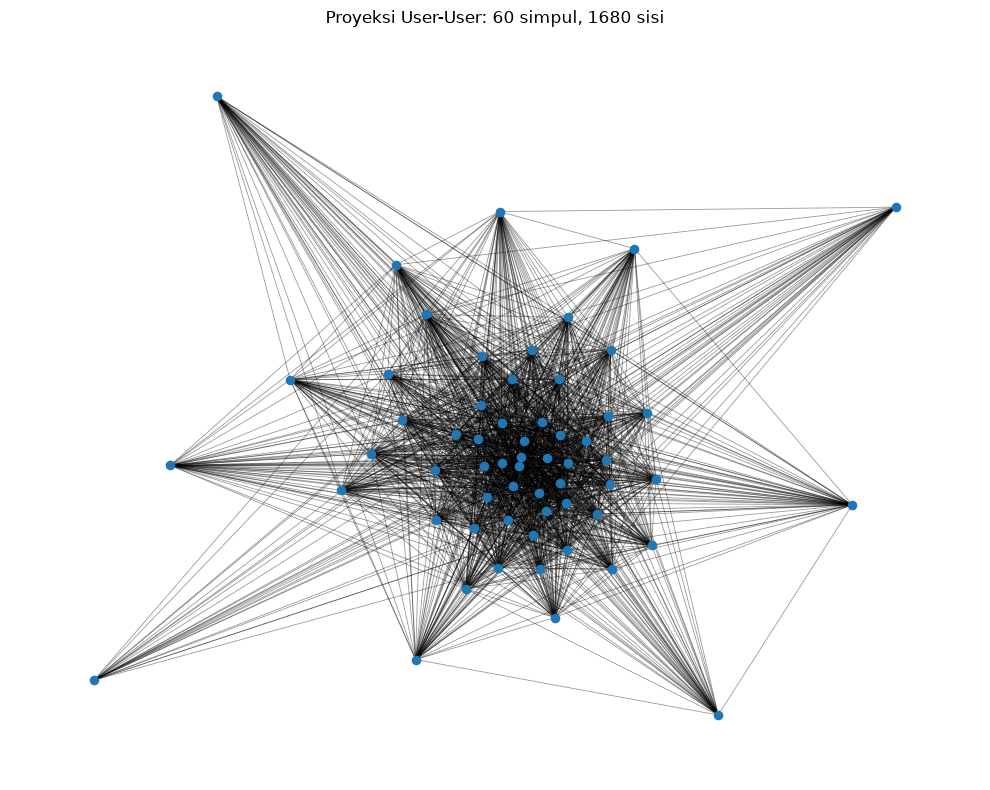

In [34]:
# ============================================================
# PROYEKSI USER-USER
# ============================================================

# Pastikan format CSR
X_user = X_user.tocsr()

# Pilih maksimal 60 user dengan jumlah item non-zero terbanyak
MAX_USERS = 60

user_degree = np.diff(X_user.indptr)
selected_user_idx = np.argsort(user_degree)[-MAX_USERS:]

# Ambil submatriks user terpilih
X_user_sample = X_user[selected_user_idx, :].tocsr()

# Bangun proyeksi User-User:
# X_user_sample @ X_user_sample.T menghitung item bersama
user_projection = X_user_sample @ X_user_sample.T

# Hilangkan diagonal (hubungan user dengan dirinya sendiri)
user_projection.setdiag(0)
user_projection.eliminate_zeros()

# Bentuk graf NetworkX
G_user = nx.Graph()

# Tambahkan node user
for idx in range(len(selected_user_idx)):
    G_user.add_node(idx)

# Tambahkan edge jika ada minimal satu item bersama
rows, cols = user_projection.nonzero()

for i, j in zip(rows, cols):
    if i < j:
        G_user.add_edge(
            i,
            j,
            weight=float(user_projection[i, j])
        )

# Visualisasi
plt.figure(figsize=(10, 8))

pos_user = nx.spring_layout(
    G_user,
    seed=42,
    k=0.5
)

nx.draw_networkx_nodes(
    G_user, pos_user,
    node_size=35,
    node_color="tab:blue"
)

nx.draw_networkx_edges(
    G_user, pos_user,
    alpha=0.4,
    width=0.6
)

plt.title(
    f"Proyeksi User-User: "
    f"{G_user.number_of_nodes()} simpul, "
    f"{G_user.number_of_edges()} sisi"
)
plt.axis("off")
plt.tight_layout()
plt.show()

**Jawaban No.4.** VSM (Vector Space Model) user memiliki ukuran matriks sebesar (879.515, 191.638), yang menunjukkan bahwa terdapat 879.515 vektor pengguna dengan 191.638 dimensi yang merepresentasikan item. Matriks ini memiliki 1.334.471 elemen tidak nol (non-zero elements atau NNZ), dengan density sebesar 0,000792% dan sparsity sebesar 99,999208%, sehingga sebagian besar elemen matriks bernilai nol. Rata-rata setiap vektor pengguna hanya memiliki 1,52 elemen tidak nol, dengan median 1 elemen dan jumlah maksimum 2.721 elemen tidak nol dalam satu vektor. Karakteristik tersebut menunjukkan bahwa interaksi pengguna terhadap item sangat jarang dan tidak merata, yaitu sebagian besar pengguna hanya berinteraksi dengan sedikit item, sementara sebagian kecil pengguna memiliki riwayat interaksi yang jauh lebih banyak. Penggunaan format penyimpanan matriks sparse CSR (Compressed Sparse Row) membuat representasi ini lebih efisien, dengan kebutuhan memori sekitar 13,54 MB, sehingga sesuai untuk mengolah data interaksi berskala besar dalam sistem rekomendasi.

### No. 5 : Membentuk VSM Item dari P1

VSM Item menggunakan informasi interaksi yang sama, tetapi sudut pandangnya dibalik. Setiap baris adalah item dan setiap kolom adalah user. Nilai bobot tetap sama dengan VSM User.

In [27]:
# Matriks VSM Item: baris=item, kolom=user
X_item = X_user.T.tocsr()

item_ids_vsm = item_ids
user_ids_vsm = user_ids

print("Dimensi matriks:", X_item.ndim)
print("Shape VSM Item:", X_item.shape)
print("Jumlah item:", X_item.shape[0])
print("Jumlah fitur user:", X_item.shape[1])
print("Jumlah nilai non-zero:", X_item.nnz)
print("Total elemen matriks:", X_item.shape[0] * X_item.shape[1])

print(
    "Sparsity:",
    1 - X_item.nnz / (X_item.shape[0] * X_item.shape[1])
)

Dimensi matriks: 2
Shape VSM Item: (191638, 879515)
Jumlah item: 191638
Jumlah fitur user: 879515
Jumlah nilai non-zero: 1334471
Total elemen matriks: 168548495570
Sparsity: 0.9999920825694973


Menyimpan VSM Item

In [28]:
save_npz(
    os.path.join(OUTPUT_DIR, "vsm_item_P1.npz"),
    X_item
)

pd.DataFrame({"itemid": item_ids_vsm}).to_csv(
    os.path.join(OUTPUT_DIR, "vsm_item_row_ids.csv"),
    index=False
)

pd.DataFrame({"visitorid": user_ids_vsm}).to_csv(
    os.path.join(OUTPUT_DIR, "vsm_item_column_ids.csv"),
    index=False
)

print("VSM Item dan metadata ID berhasil disimpan.")

VSM Item dan metadata ID berhasil disimpan.


**Analisis karakteristik VSM Item**

Kita menghitung berapa banyak user yang berinteraksi dengan setiap item, serta total bobot interaksinya. Informasi ini membantu menjelaskan apakah interaksi terkonsentrasi pada sejumlah kecil item atau tersebar pada banyak item.

In [29]:
import numpy as np
import pandas as pd
from scipy.sparse import csr_matrix, issparse

# ============================================================
# KARAKTERISTIK VECTOR SPACE MODEL (VSM ITEM)
# ============================================================

# Pastikan matriks menggunakan format CSR
if not issparse(X_item):
    X_item = csr_matrix(X_item)
else:
    X_item = X_item.tocsr()

# Dimensi matriks
n_items, n_users = X_item.shape

# Jumlah elemen non-zero
nnz = X_item.nnz

# Total elemen matriks
total_elements = n_items * n_users

# Density dan sparsity
density = (
    nnz / total_elements * 100
    if total_elements > 0 else 0
)
sparsity = 100 - density if total_elements > 0 else 0

# Jumlah NNZ untuk setiap vektor item
nnz_per_vector = np.diff(X_item.indptr)

# Statistik NNZ per vektor
mean_nnz = (
    np.mean(nnz_per_vector)
    if n_items > 0 else 0
)
median_nnz = (
    np.median(nnz_per_vector)
    if n_items > 0 else 0
)
max_nnz = (
    np.max(nnz_per_vector)
    if n_items > 0 else 0
)

# Memori CSR: data + indeks kolom + pointer baris
memory_bytes = (
    X_item.data.nbytes
    + X_item.indices.nbytes
    + X_item.indptr.nbytes
)
memory_mb = memory_bytes / (1024 ** 2)

# ============================================================
# TABEL KARAKTERISTIK VSM ITEM
# ============================================================

vsm_item_characteristics = pd.DataFrame({
    "Karakteristik": [
        "shape",
        "jumlah vektor",
        "dimensi vektor",
        "nnz",
        "density",
        "sparsity (%)",
        "rata2 nnz/vektor",
        "median nnz/vektor",
        "maks nnz/vektor",
        "memori CSR (MB)"
    ],
    "VSM": [
        str(X_item.shape),
        f"{n_items:,}",
        f"{n_users:,}",
        f"{nnz:,}",
        f"{density:.6f}%",
        f"{sparsity:.6f}",
        f"{mean_nnz:.2f}",
        f"{median_nnz:.2f}",
        f"{max_nnz:,}",
        f"{memory_mb:.2f}"
    ]
})

display(
    vsm_item_characteristics.set_index("Karakteristik")
)

,VSM
Karakteristik,
shape,"(191638, 879515)"
jumlah vektor,"191,638"
dimensi vektor,"879,515"
nnz,"1,334,471"
density,0.000792%
sparsity (%),99.999208
rata2 nnz/vektor,6.96
median nnz/vektor,2.00
maks nnz/vektor,"1,729"


Visualisasi jumlah user per item

In [31]:
# ============================================================
# STATISTIK AKTIVITAS ITEM
# ============================================================

item_activity = (
    user_item_agg.groupby("itemid")
    .agg(
        jumlah_user=("visitorid", "nunique"),
        total_bobot=("weight", "sum")
    )
    .reset_index()
)

print("Statistik jumlah user per item:")
display(
    item_activity["jumlah_user"]
    .describe()
    .to_frame("statistik")
)

print("\n10 item dengan jumlah user terbanyak:")
display(
    item_activity
    .sort_values("jumlah_user", ascending=False)
    .head(10)
)

Statistik jumlah user per item:


,statistik
count,191638.000000
mean,6.963499
std,18.745010
min,1.000000
25%,1.000000
50%,2.000000
75%,6.000000
max,1729.000000



10 item dengan jumlah user terbanyak:


,itemid,jumlah_user,total_bobot
170736,5411,1729,1943.0
123523,370653,1058,1253.0
95624,309778,957,1629.0
90261,298009,936,1149.0
107601,335975,852,1046.0
190247,96924,808,953.0
116044,354233,741,919.0
71585,257040,731,1326.0
164952,461686,704,2067.0
54418,219512,651,907.0


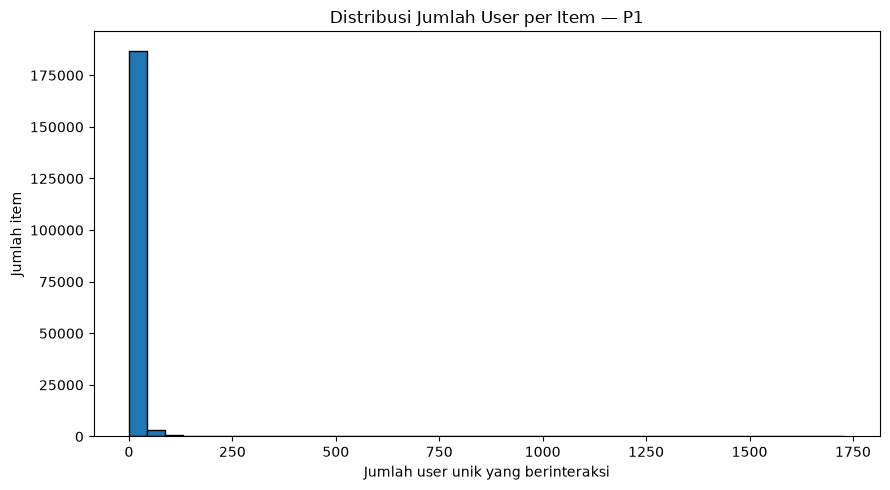

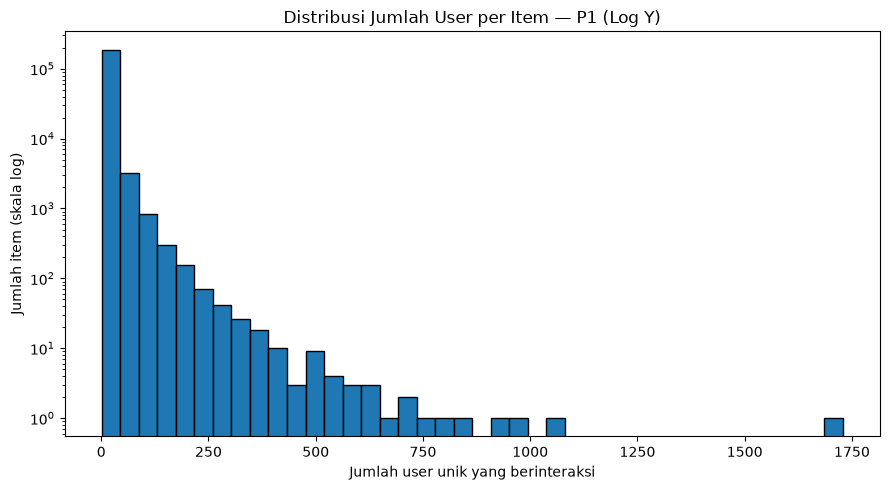

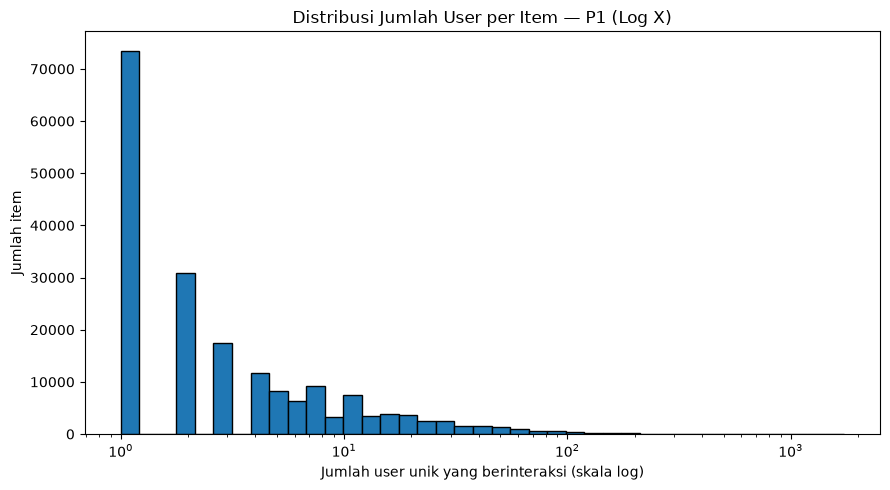

In [88]:
import matplotlib.pyplot as plt
import numpy as np

jumlah_user = item_activity["jumlah_user"]
jumlah_user_positif = jumlah_user[jumlah_user > 0]

# ============================================================
# 1. HISTOGRAM BIASA
# ============================================================
plt.figure(figsize=(9, 5))
plt.hist(jumlah_user, bins=40, edgecolor="black")
plt.title("Distribusi Jumlah User per Item — P1")
plt.xlabel("Jumlah user unik yang berinteraksi")
plt.ylabel("Jumlah item")
plt.tight_layout()
plt.show()

# ============================================================
# 2. HISTOGRAM DENGAN SKALA LOGARITMIK PADA SUMBU Y
# ============================================================
plt.figure(figsize=(9, 5))
plt.hist(jumlah_user, bins=40, edgecolor="black")
plt.yscale("log")
plt.title("Distribusi Jumlah User per Item — P1 (Log Y)")
plt.xlabel("Jumlah user unik yang berinteraksi")
plt.ylabel("Jumlah item (skala log)")
plt.tight_layout()
plt.show()

# ============================================================
# 3. HISTOGRAM DENGAN SKALA LOGARITMIK PADA SUMBU X
# ============================================================
if not jumlah_user_positif.empty:
    bins_log = np.logspace(
        np.log10(jumlah_user_positif.min()),
        np.log10(jumlah_user_positif.max()),
        40
    )

    plt.figure(figsize=(9, 5))
    plt.hist(jumlah_user_positif, bins=bins_log, edgecolor="black")
    plt.xscale("log")
    plt.title("Distribusi Jumlah User per Item — P1 (Log X)")
    plt.xlabel("Jumlah user unik yang berinteraksi (skala log)")
    plt.ylabel("Jumlah item")
    plt.tight_layout()
    plt.show()

**Plot graf bipartit dari perspektif VSM Item**

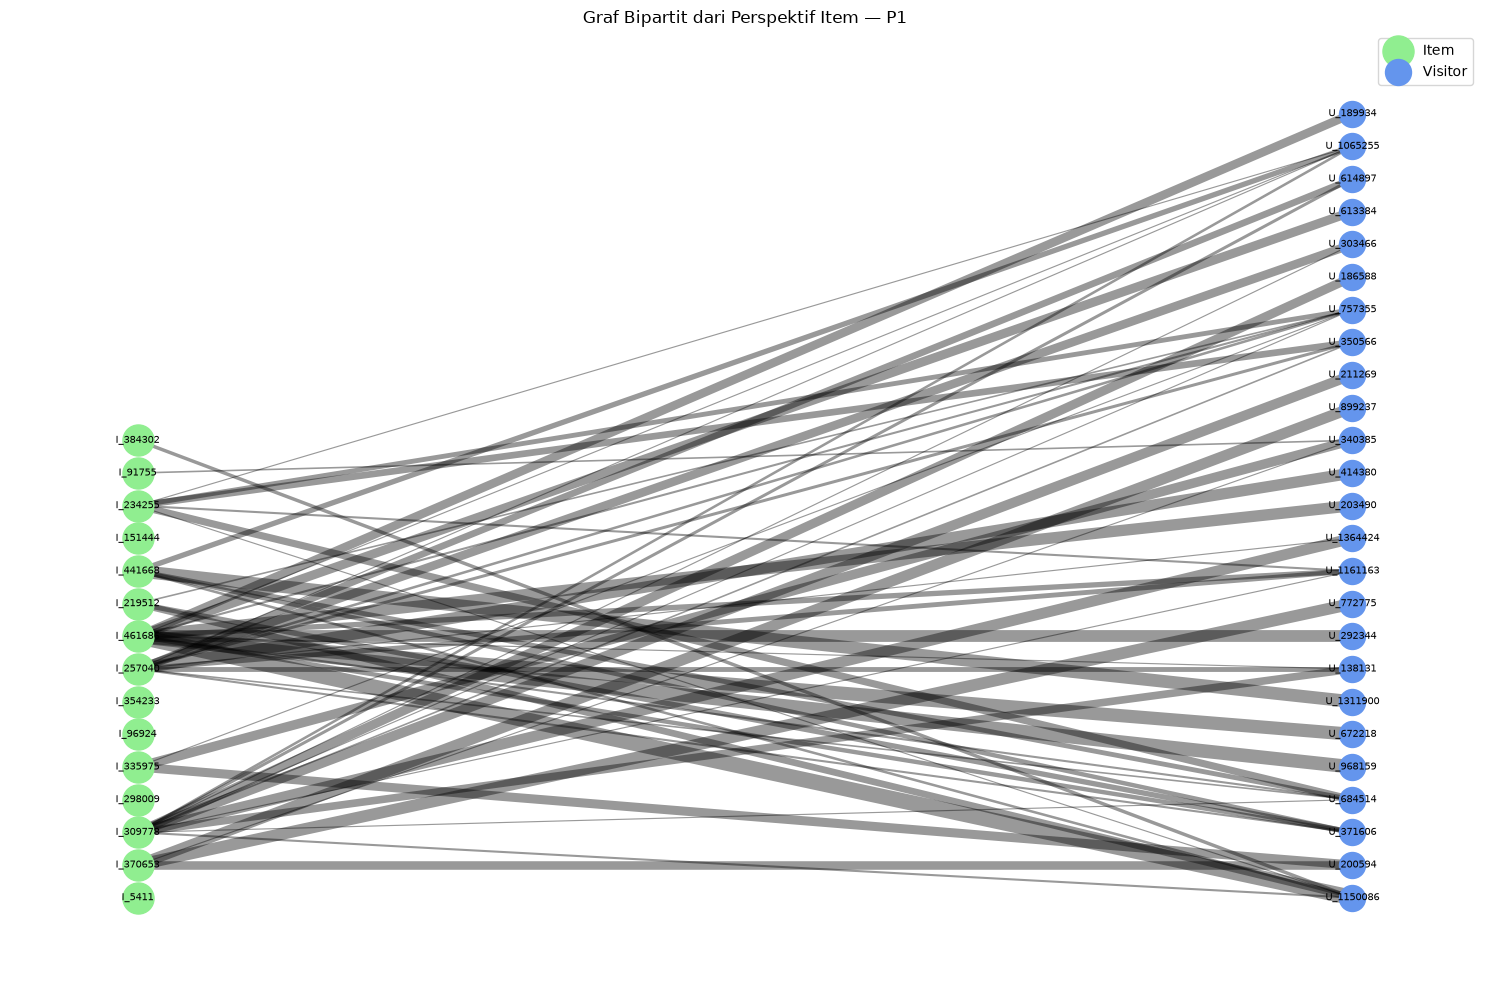

Jumlah node pada graf item-view: 40
Jumlah edge pada graf item-view: 59


In [33]:
top_items_graph = item_activity.nlargest(
    min(15, len(item_activity)), "jumlah_user"
)["itemid"]

edges_item_view = user_item_agg[
    user_item_agg["itemid"].isin(top_items_graph)
].copy()

# Batasi user agar plot tidak terlalu padat
top_users_graph = (
    edges_item_view.groupby("visitorid")["weight"]
    .sum()
    .nlargest(25)
    .index
)

edges_item_view = edges_item_view[
    edges_item_view["visitorid"].isin(top_users_graph)
]

G_item = nx.Graph()

for iid in top_items_graph:
    G_item.add_node(f"I_{iid}", node_type="item")

for uid in top_users_graph:
    G_item.add_node(f"U_{uid}", node_type="user")

for row in edges_item_view.itertuples(index=False):
    G_item.add_edge(
        f"I_{row.itemid}",
        f"U_{row.visitorid}",
        weight=float(row.weight)
    )

items_draw = [
    n for n, d in G_item.nodes(data=True)
    if d["node_type"] == "item"
]
users_draw = [
    n for n, d in G_item.nodes(data=True)
    if d["node_type"] == "user"
]

pos_item = {}
for idx, node in enumerate(items_draw):
    pos_item[node] = (0, idx)
for idx, node in enumerate(users_draw):
    pos_item[node] = (1, idx)

plt.figure(figsize=(15, 10))

nx.draw_networkx_nodes(
    G_item, pos_item,
    nodelist=items_draw,
    node_color="lightgreen",
    node_size=500,
    label="Item"
)

nx.draw_networkx_nodes(
    G_item, pos_item,
    nodelist=users_draw,
    node_color="cornflowerblue",
    node_size=350,
    label="Visitor"
)

nx.draw_networkx_edges(
    G_item, pos_item,
    width=[
        0.5 + G_item[u][v]["weight"] / 3
        for u, v in G_item.edges()
    ],
    alpha=0.4
)

nx.draw_networkx_labels(G_item, pos_item, font_size=7)

plt.title("Graf Bipartit dari Perspektif Item — P1")
plt.legend()
plt.axis("off")
plt.tight_layout()
plt.show()

print("Jumlah node pada graf item-view:", G_item.number_of_nodes())
print("Jumlah edge pada graf item-view:", G_item.number_of_edges())

mengambil maksimal 12 item dengan jumlah user terbanyak. Dua item terhubung jika pernah diakses oleh user yang sama.

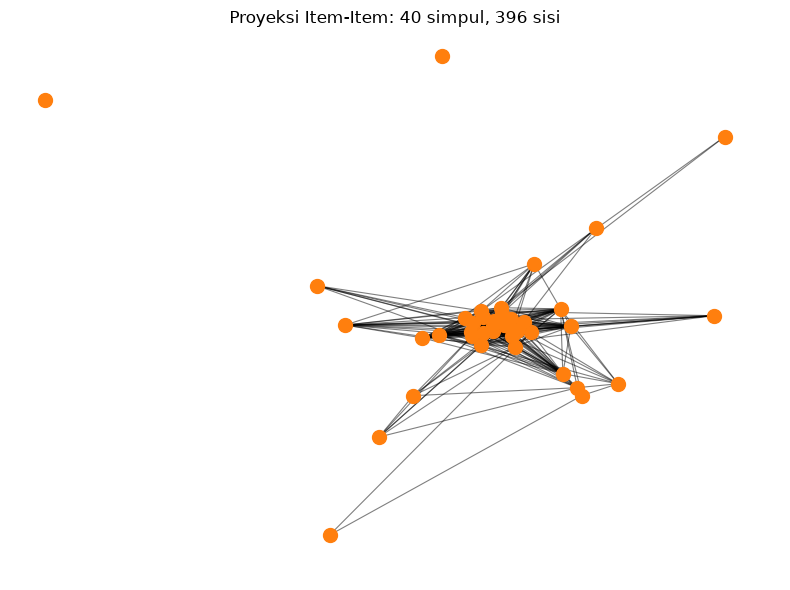

In [87]:
# ============================================================
# PROYEKSI ITEM-ITEM
# ============================================================

X_item = X_item.tocsr()

MAX_ITEMS = 40

# Jumlah user yang berinteraksi dengan setiap item
item_degree = np.diff(X_item.indptr)

# Pilih maksimal 12 item dengan user terbanyak
selected_item_idx = np.argsort(item_degree)[-MAX_ITEMS:]

# Submatriks item terpilih
X_item_sample = X_item[selected_item_idx, :].tocsr()

# X_item_sample @ X_item_sample.T menghitung user bersama
item_projection = X_item_sample @ X_item_sample.T

# Hapus hubungan item dengan dirinya sendiri
item_projection.setdiag(0)
item_projection.eliminate_zeros()

# Bentuk graf
G_item = nx.Graph()

for idx in range(len(selected_item_idx)):
    G_item.add_node(idx)

rows, cols = item_projection.nonzero()

for i, j in zip(rows, cols):
    if i < j:
        G_item.add_edge(
            i,
            j,
            weight=float(item_projection[i, j])
        )

# Visualisasi
plt.figure(figsize=(8, 6))

pos_item = nx.spring_layout(
    G_item,
    seed=42,
    k=0.8
)

nx.draw_networkx_nodes(
    G_item, pos_item,
    node_size=100,
    node_color="tab:orange"
)

nx.draw_networkx_edges(
    G_item, pos_item,
    alpha=0.5,
    width=0.8
)

plt.title(
    f"Proyeksi Item-Item: "
    f"{G_item.number_of_nodes()} simpul, "
    f"{G_item.number_of_edges()} sisi"
)
plt.axis("off")
plt.tight_layout()
plt.show()

**Jawaban No.5** VSM (Vector Space Model) item memiliki ukuran matriks sebesar (191.638, 879.515), yang menunjukkan bahwa terdapat 191.638 vektor item dengan 879.515 dimensi yang merepresentasikan pengguna. Matriks ini memiliki 1.334.471 elemen tidak nol (non-zero elements atau NNZ), dengan density sebesar 0,000792% dan sparsity sebesar 99,999208%, sehingga sebagian besar elemen matriks bernilai nol. Rata-rata setiap vektor item memiliki 6,96 elemen tidak nol, dengan median 2 elemen dan jumlah maksimum 1.729 elemen tidak nol dalam satu vektor. Hal ini menunjukkan bahwa jumlah interaksi pada setiap item bervariasi, dengan sebagian besar item hanya berinteraksi dengan sedikit pengguna, sementara beberapa item memiliki interaksi yang jauh lebih tinggi. Meskipun matriks memiliki dimensi yang besar dan tingkat sparsity yang sangat tinggi, penggunaan format penyimpanan CSR (Compressed Sparse Row) memungkinkan representasi data yang lebih efisien dengan kebutuhan memori sekitar 10,91 MB. Karakteristik ini mendukung pemrosesan data interaksi item dalam jumlah besar sebagai dasar analisis kemiripan dan pengembangan sistem rekomendasi berbasis item.

### Soal No.6 :  PROYEKSI YANG LEBIH BAIK (EFEKTIF DAN EFISIEN)

Untuk menentukan apakah proyeksi User–User atau Item–Item lebih baik, dilakukan pengukuran berdasarkan beberapa aspek berikut:

1. **Keterhubungan Graf** — dievaluasi melalui jumlah sisi (*edges*), kepadatan graf (*density*), dan jumlah simpul yang terisolasi (*isolated nodes*).

2. **Efisiensi Komputasi** — diukur berdasarkan waktu yang dibutuhkan untuk membentuk proyeksi dan penggunaan memori selama proses komputasi.

3. **Kualitas Struktur Graf** — dianalisis melalui jumlah komponen terhubung (*connected components*) dan rata-rata derajat simpul (*average degree*) untuk mengetahui pola hubungan dalam graf.

4. **Kelayakan untuk Rekomendasi** — dinilai berdasarkan jumlah dan pola hubungan yang dapat dimanfaatkan untuk menemukan pengguna dengan pola interaksi serupa atau item yang memiliki kesamaan berdasarkan interaksi pengguna.

**Perbandingan Proyeksi**

In [36]:
import time
import numpy as np
import pandas as pd
import networkx as nx

# ============================================================
# 1. FUNGSI ANALISIS KARAKTERISTIK GRAF
# ============================================================

def analyze_projection(G, projection_name):
    n_nodes = G.number_of_nodes()
    n_edges = G.number_of_edges()

    # Density graf
    density = nx.density(G) if n_nodes > 1 else 0

    # Derajat simpul
    degrees = np.array([degree for _, degree in G.degree()])

    avg_degree = degrees.mean() if len(degrees) else 0
    max_degree = degrees.max() if len(degrees) else 0

    # Simpul terisolasi
    isolates = list(nx.isolates(G))
    isolate_count = len(isolates)

    # Komponen terhubung
    components = list(nx.connected_components(G))
    n_components = len(components)

    largest_component = (
        max(len(c) for c in components)
        if components else 0
    )

    largest_component_pct = (
        largest_component / n_nodes * 100
        if n_nodes > 0 else 0
    )

    # Proporsi simpul yang memiliki setidaknya satu sisi
    active_nodes_pct = (
        (n_nodes - isolate_count) / n_nodes * 100
        if n_nodes > 0 else 0
    )

    return {
        "Proyeksi": projection_name,
        "Jumlah simpul": n_nodes,
        "Jumlah sisi": n_edges,
        "Density (%)": density * 100,
        "Rata-rata derajat": avg_degree,
        "Derajat maksimum": max_degree,
        "Simpul terisolasi": isolate_count,
        "Simpul aktif (%)": active_nodes_pct,
        "Komponen terhubung": n_components,
        "Simpul komponen terbesar (%)": largest_component_pct
    }


# ============================================================
# 2. ANALISIS USER-USER DAN ITEM-ITEM
# ============================================================

user_result = analyze_projection(G_user, "User-User")
item_result = analyze_projection(G_item, "Item-Item")

comparison = pd.DataFrame([
    user_result,
    item_result
]).set_index("Proyeksi")

display(comparison.round(4))

,Jumlah simpul,Jumlah sisi,Density (%),Rata-rata derajat,Derajat maksimum,Simpul terisolasi,Simpul aktif (%),Komponen terhubung,Simpul komponen terbesar (%)
Proyeksi,,,,,,,,,
User-User,60,1680,94.9153,56.0,59,0,100.0000,1,100.0000
Item-Item,12,24,36.3636,4.0,8,2,83.3333,3,83.3333


**Tentukan proyeksi yang lebih baik berdasarkan struktur graf**

membandingkan proporsi simpul aktif, density, dan rata-rata derajat.membandingkan proporsi simpul aktif, density, dan rata-rata derajat.

In [37]:
# ============================================================
# 3. PERBANDINGAN INDIKATOR STRUKTUR
# ============================================================

print("========== HASIL PERBANDINGAN ==========")

for name, result in [
    ("User-User", user_result),
    ("Item-Item", item_result)
]:
    print(f"\nProyeksi {name}")
    print(f"Jumlah sisi             : {result['Jumlah sisi']}")
    print(f"Density                  : {result['Density (%)']:.4f}%")
    print(f"Rata-rata derajat        : {result['Rata-rata derajat']:.2f}")
    print(f"Simpul terisolasi        : {result['Simpul terisolasi']}")
    print(f"Simpul aktif             : {result['Simpul aktif (%)']:.2f}%")
    print(
        "Komponen terbesar       : "
        f"{result['Simpul komponen terbesar (%)']:.2f}% simpul"
    )

# Perbandingan berdasarkan jumlah sisi dan simpul aktif
if (
    user_result["Simpul aktif (%)"] > item_result["Simpul aktif (%)"]
    and user_result["Jumlah sisi"] > item_result["Jumlah sisi"]
):
    print(
        "\nKesimpulan struktural: User-User lebih terhubung "
        "pada graf yang sedang dianalisis."
    )
elif (
    item_result["Simpul aktif (%)"] > user_result["Simpul aktif (%)"]
    and item_result["Jumlah sisi"] > user_result["Jumlah sisi"]
):
    print(
        "\nKesimpulan struktural: Item-Item lebih terhubung "
        "pada graf yang sedang dianalisis."
    )
else:
    print(
        "\nKesimpulan: tidak ada pemenang berdasarkan dua indikator "
        "tersebut saja. Periksa seluruh metrik dan tujuan analisis."
    )

========== HASIL PERBANDINGAN ==========

Proyeksi User-User
Jumlah sisi             : 1680
Density                  : 94.9153%
Rata-rata derajat        : 56.00
Simpul terisolasi        : 0
Simpul aktif             : 100.00%
Komponen terbesar       : 100.00% simpul

Proyeksi Item-Item
Jumlah sisi             : 24
Density                  : 36.3636%
Rata-rata derajat        : 4.00
Simpul terisolasi        : 2
Simpul aktif             : 83.33%
Komponen terbesar       : 83.33% simpul

Kesimpulan struktural: User-User lebih terhubung pada graf yang sedang dianalisis.


Visualisasi Perbandingan Metriks

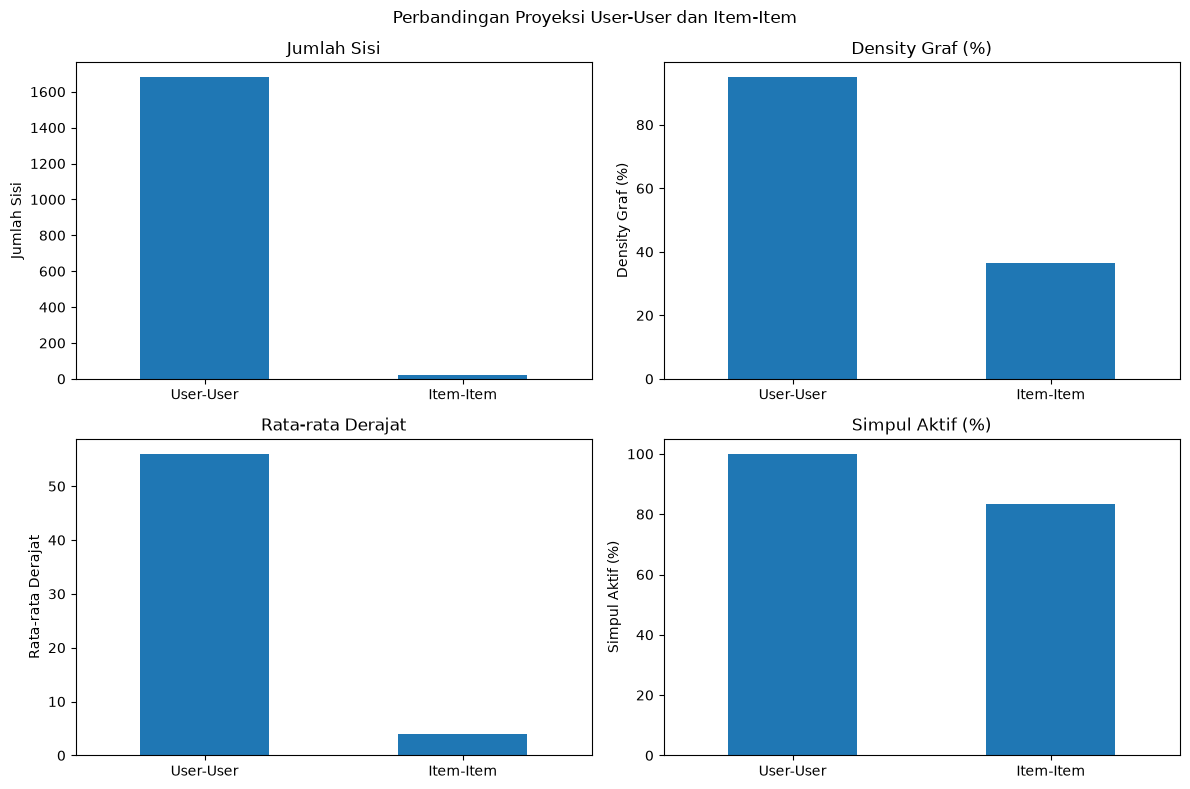

In [38]:
import matplotlib.pyplot as plt

metrics = [
    ("Jumlah sisi", "Jumlah Sisi"),
    ("Density (%)", "Density Graf (%)"),
    ("Rata-rata derajat", "Rata-rata Derajat"),
    ("Simpul aktif (%)", "Simpul Aktif (%)")
]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, (column, title) in zip(axes.flat, metrics):
    comparison[column].plot(kind="bar", ax=ax)
    ax.set_title(title)
    ax.set_ylabel(title)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=0)

plt.suptitle("Perbandingan Proyeksi User-User dan Item-Item")
plt.tight_layout()
plt.show()

**Jawaban No.6** Proyeksi User-User lebih baik dibandingkan proyeksi Item-Item berdasarkan karakteristik struktural graf yang dianalisis karena memiliki tingkat keterhubungan yang lebih tinggi. Hal ini terlihat dari jumlah sisi sebanyak 1.680 dengan density 94,9153%, rata-rata derajat 56, serta tidak adanya simpul terisolasi, sehingga seluruh simpul pengguna aktif dan tergabung dalam satu komponen terhubung terbesar. Sebaliknya, proyeksi Item-Item hanya memiliki 24 sisi dengan density 36,3636%, rata-rata derajat 4, dan dua simpul terisolasi, yang menunjukkan bahwa sebagian item memiliki keterhubungan lebih terbatas. Keterhubungan yang tinggi pada proyeksi User-User mengindikasikan adanya lebih banyak hubungan kemiripan antarpengguna berdasarkan interaksi mereka terhadap item, sehingga berpotensi memberikan lebih banyak kandidat pengguna serupa untuk mendukung proses rekomendasi.

### Soal No.7 : Perhitungan Similarity yang akan disimpan ke Neo4j

**Pemilihan user acuan** dipakai oleh soal no 7 dan soal bagian analysis

User acuan dipilih secara otomatis menggunakan metode maximum-degree selection, yaitu memilih user dengan jumlah item yang berinteraksi paling banyak berdasarkan gabungan data periode P1 dan P2. Pemilihan ini dilakukan dengan menghitung jumlah item unik yang berinteraksi dengan setiap user pada kedua periode tersebut, kemudian menetapkan user dengan jumlah interaksi tertinggi sebagai user acuan untuk perhitungan cosine similarity. Metode ini bertujuan memperoleh user dengan riwayat interaksi yang relatif lengkap sehingga kemiripannya dengan user lain dapat dianalisis.

Perhitungan kemiripan antar pengguna menggunakan metode Cosine Similarity, yaitu metode yang mengukur tingkat kemiripan dua vektor berdasarkan sudut di antara keduanya. Dalam penelitian ini, setiap pengguna direpresentasikan sebagai vektor pada VSM User yang berisi bobot interaksi terhadap item. Cosine Similarity dipilih karena dapat membandingkan pola preferensi pengguna tanpa terlalu dipengaruhi oleh perbedaan jumlah total interaksi.

In [97]:
import numpy as np
import pandas as pd
from sklearn.metrics.pairwise import cosine_similarity

# Pastikan user_ids mengikuti urutan baris X_user.
# Gunakan variabel user_ids yang dipakai saat membangun X_user.

X_user = X_user.tocsr()

# Pilih user acuan: user dengan jumlah item non-zero terbanyak
user_degree = np.diff(X_user.indptr)
reference_idx = int(np.argmax(user_degree))
reference_id = str(user_ids[reference_idx])

# Hitung cosine similarity user acuan dengan semua user
similarities = cosine_similarity(
    X_user[reference_idx],
    X_user
).ravel()

# Urutkan similarity tertinggi, kecuali user acuan itu sendiri
similarities[reference_idx] = -1

top_indices = np.argsort(similarities)[::-1][:5]

top5_users = pd.DataFrame({
    "reference_id": reference_id,
    "similar_id": [str(user_ids[i]) for i in top_indices],
    "similarity": [float(similarities[i]) for i in top_indices]
})

print("User acuan:", reference_id)
print("\n5 user dengan cosine similarity tertinggi:")
display(top5_users)

User acuan: 1150086

5 user dengan cosine similarity tertinggi:


,reference_id,similar_id,similarity
0,1150086,530559,0.166933
1,1150086,371606,0.159585
2,1150086,1021751,0.154704
3,1150086,778604,0.154704
4,1150086,1136041,0.154704


**Simpan similarity ke Neo4j**

Kode ini membuat relationship SIMILAR_TO dari user acuan ke masing-masing lima user teratas. Relationship interaksi asli tidak dihapus.

In [98]:
SAVE_SIMILARITY_QUERY = """
UNWIND $rows AS row
MATCH (a:Visitor {visitorId: row.reference_id})
MATCH (b:Visitor {visitorId: row.similar_id})
MERGE (a)-[r:SIMILAR_TO]->(b)
SET r.cosine_similarity = toFloat(row.similarity),
    r.method = 'cosine_similarity'
RETURN count(r) AS relationships_saved
"""

with driver.session() as session:
    result = session.run(
        SAVE_SIMILARITY_QUERY,
        rows=top5_users.to_dict(orient="records")
    )
    print(result.single()["relationships_saved"])

5


**CYPHER SQL untuk mendapatkan 5 records dengan similarity tertinggi**

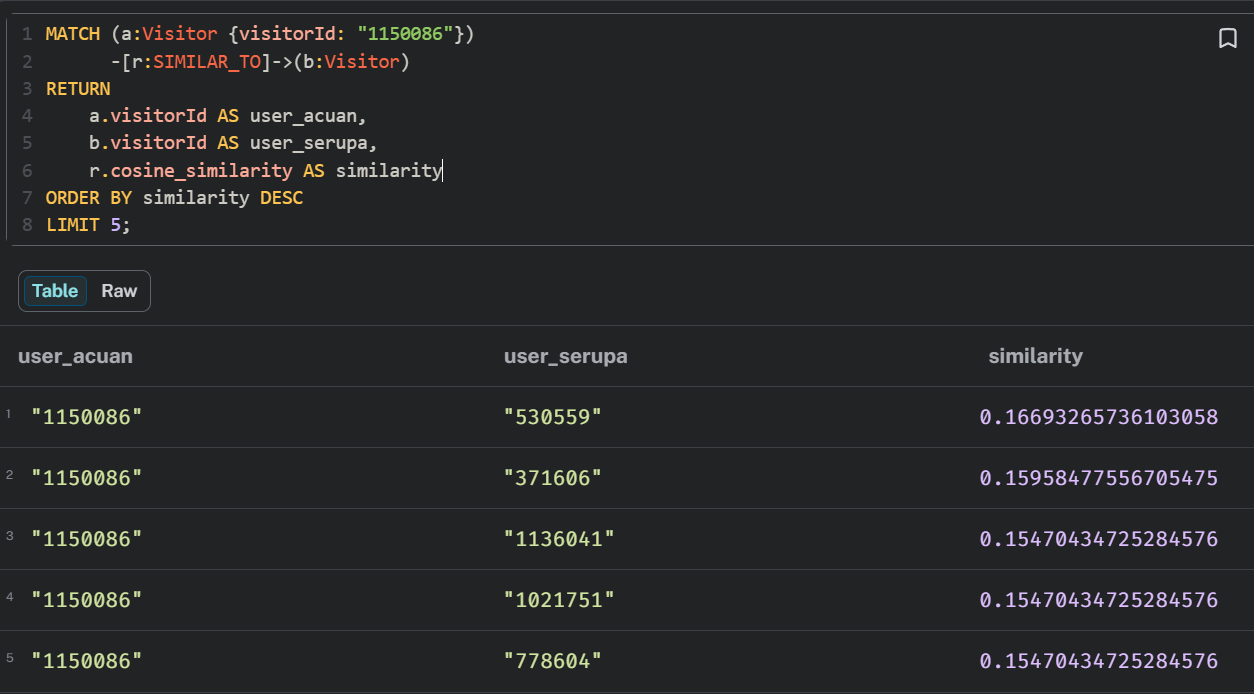

**Jawaban No.7.** 

(a) Cypher untuk mendapatkan 5 records dengan similarity tertinggi

Perhitungan cosine similarity dilakukan terlebih dahulu menggunakan Python berdasarkan VSM User, dengan user 1150086 sebagai user acuan. Lima user dengan nilai kemiripan tertinggi kemudian diperoleh, yaitu 530559 (0,166933), 371606 (0,159585), 1021751 (0,154704), 778604 (0,154704), dan 1136041 (0,154704). Selanjutnya, nilai similarity tersebut disimpan ke Neo4j sebagai relasi antarnode Visitor.

(b) Menampilkan nilai similarity pada graf yang telah ada

Setelah nilai cosine similarity dihitung di Python, hasilnya disimpan ke Neo4j sebagai relasi SIMILARITY beserta properti score. Dapat dilihat hasil query sama dengan hasil perhitungan similarity di python



### Soal No.8 : kondisi graf sebelum dan sesudah similarity

**Graf sebelum similarity pada user acuan**

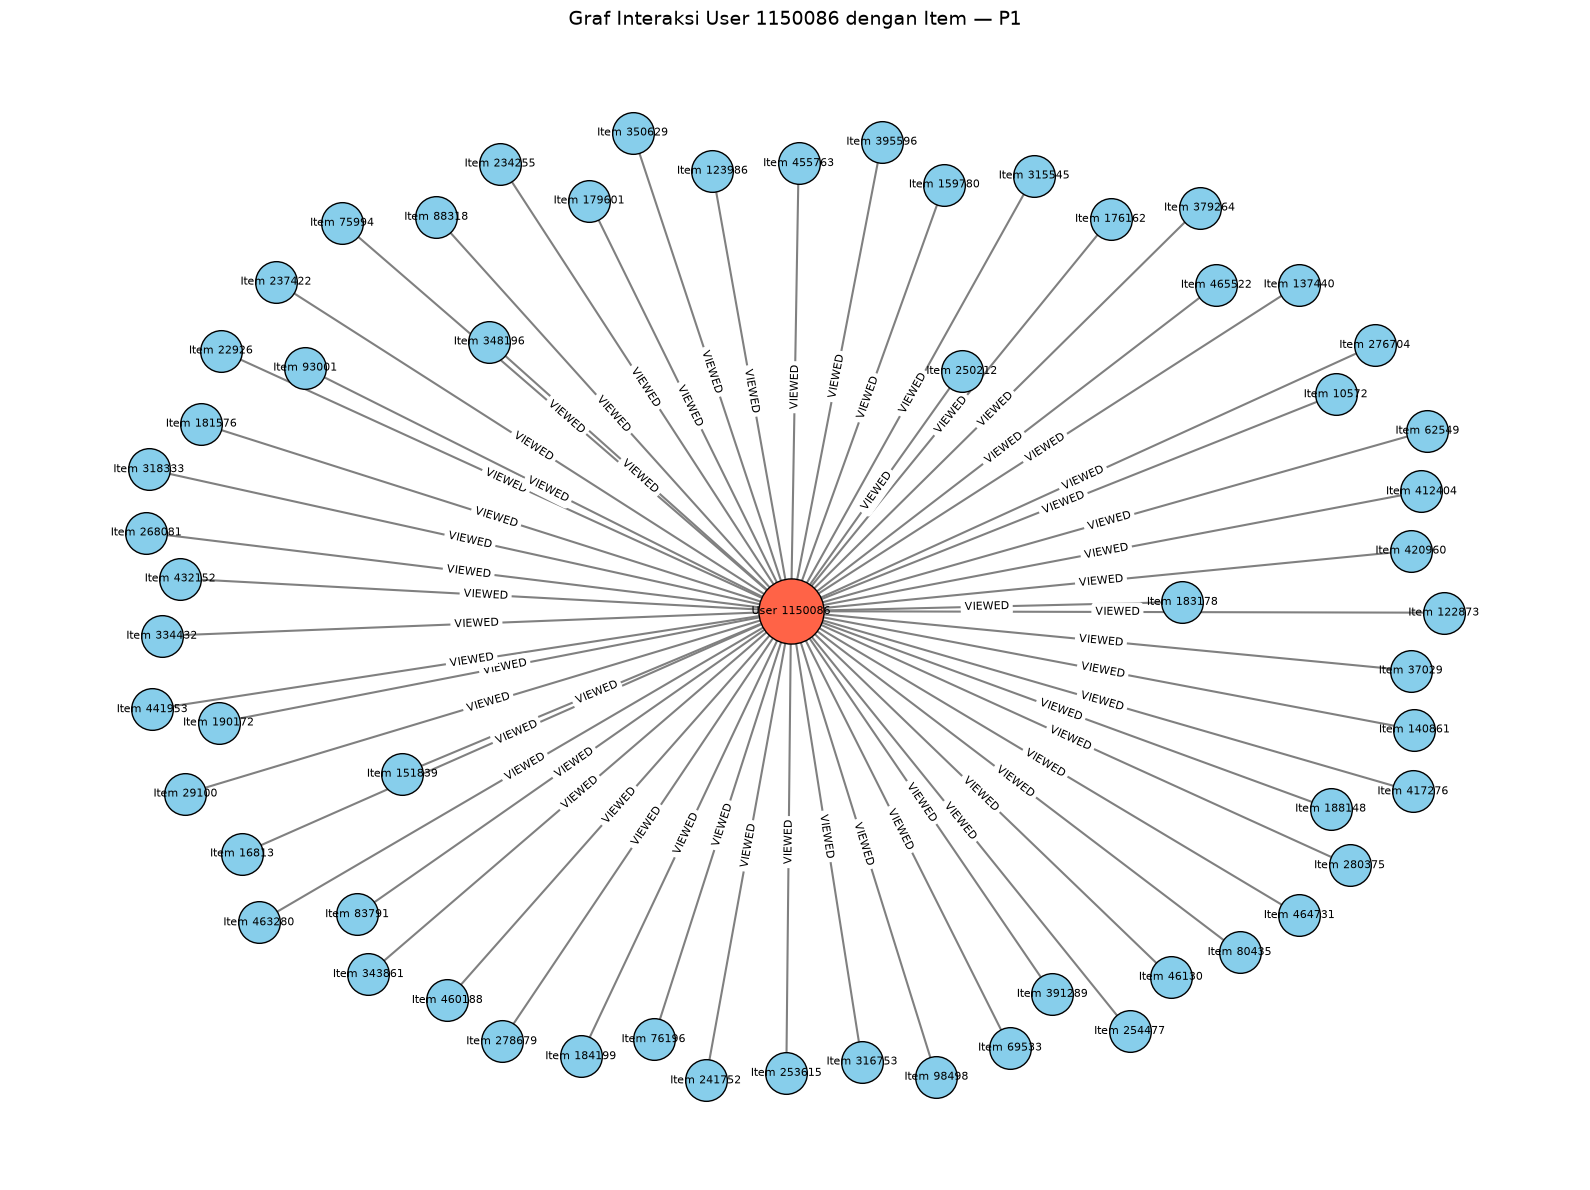

Jumlah node: 59
Jumlah edge: 58


In [101]:
# ============================================================
# 1. IMPORT LIBRARY
# ============================================================
import networkx as nx
import matplotlib.pyplot as plt

# ============================================================
# 2. MEMBANGUN GRAF
# ============================================================
G = nx.Graph()

user_id = 1150086
user_node = f"User {user_id}"

# Tambahkan node user
G.add_node(user_node, node_type="user")

# Tambahkan node item dan edge dari DataFrame
for _, row in interaction_df.iterrows():
    item_node = f"Item {row['item_id']}"

    G.add_node(item_node, node_type="item")
    G.add_edge(
        user_node,
        item_node,
        relationship=row["jenis_relasi"]
    )

# ============================================================
# 3. VISUALISASI GRAF
# ============================================================
plt.figure(figsize=(16, 12))

pos = nx.spring_layout(G, seed=42, k=1.2)

# Pisahkan node user dan item
user_nodes = [
    node for node, data in G.nodes(data=True)
    if data["node_type"] == "user"
]

item_nodes = [
    node for node, data in G.nodes(data=True)
    if data["node_type"] == "item"
]

# Gambar node
nx.draw_networkx_nodes(
    G, pos,
    nodelist=user_nodes,
    node_size=2200,
    node_color="tomato",
    edgecolors="black"
)

nx.draw_networkx_nodes(
    G, pos,
    nodelist=item_nodes,
    node_size=900,
    node_color="skyblue",
    edgecolors="black"
)

# Gambar edge
nx.draw_networkx_edges(
    G, pos,
    edge_color="gray",
    width=1.5
)

# Label node
nx.draw_networkx_labels(
    G, pos,
    font_size=8
)

# Label relasi
edge_labels = nx.get_edge_attributes(G, "relationship")

nx.draw_networkx_edge_labels(
    G, pos,
    edge_labels=edge_labels,
    font_size=8
)

plt.title(
    f"Graf Interaksi User {user_id} dengan Item — P1",
    fontsize=14
)

plt.axis("off")
plt.tight_layout()
plt.show()

print("Jumlah node:", G.number_of_nodes())
print("Jumlah edge:", G.number_of_edges())

**Graf setelah similarity pada user acuan**

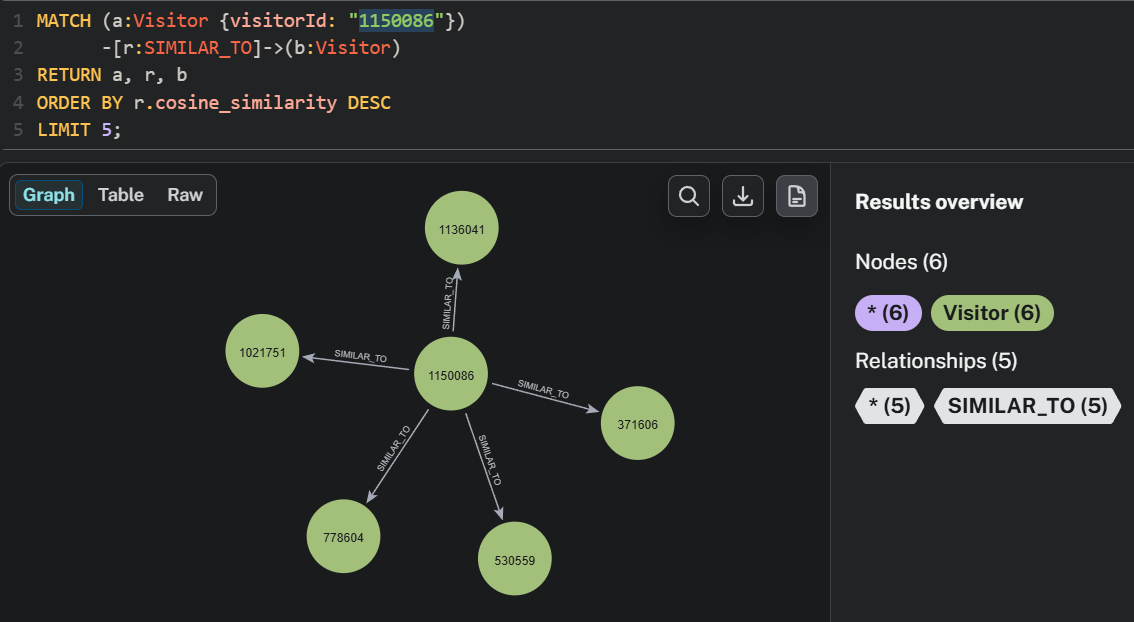

## **Analytics**

**Membaca data P1 dan P2**

In [63]:
P1_PATH = "/content/hasil_analisis/retailrocket_P1_training.csv"
P2_PATH = "/content/hasil_analisis/retailrocket_P2_testing.csv"

train_df = pd.read_csv(P1_PATH)
test_df = pd.read_csv(P2_PATH)

print("Data P1:", train_df.shape)
print("Data P2:", test_df.shape)

display(train_df.head())
display(test_df.head())

Data P1: (1716085, 5)
Data P2: (372163, 5)


,timestamp,visitorid,event,itemid,period
0,1433221332117,257597,view,355908,P1
1,1433224214164,992329,view,248676,P1
2,1433221999827,111016,view,318965,P1
3,1433221955914,483717,view,253185,P1
4,1433221337106,951259,view,367447,P1


,timestamp,visitorid,event,itemid,period
0,1438744981471,1289418,view,17189,P2
1,1438743436990,44789,view,57577,P2
2,1438743486283,683790,view,369981,P2
3,1438741548865,1244885,view,100644,P2
4,1438743783838,409555,view,323831,P2


**Memeriksa node dan relasi yang berhasil dibuat**

In [64]:
with driver.session() as session:
    result = session.run("""
        MATCH (v:Visitor)-[r]->(i:Item)
        RETURN
            type(r) AS jenis_relasi,
            count(r) AS jumlah
        ORDER BY jumlah DESC
    """)

    display(pd.DataFrame([record.data() for record in result]))

,jenis_relasi,jumlah
0,INTERACTED,2088248
1,VIEWED,1836747
2,ADDED_TO_CART,46826
3,BOUGHT,15456


**Menggunakan graf yang sudah dibuat sebelumnya di Neo4j**

In [67]:
with driver.session() as session:
    result = session.run("""
        CALL gds.graph.list()
        YIELD graphName, nodeCount, relationshipCount
        WHERE graphName = 'retailKNNGraph'
        RETURN graphName, nodeCount, relationshipCount
    """)

    for record in result:
        print(record.data())

{'graphName': 'retailKNNGraph', 'nodeCount': 2446407, 'relationshipCount': 7974554}


**Melakukan embedding di Neo4j**

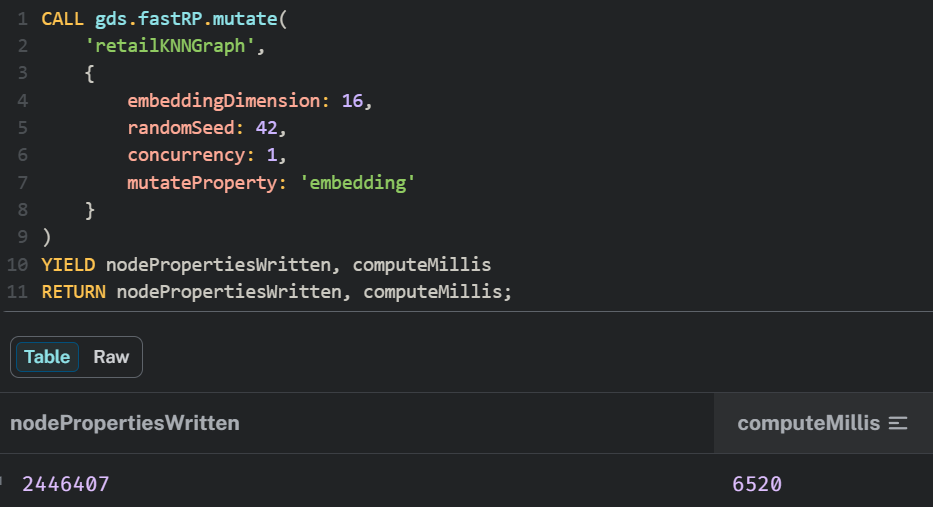

embedding digunakan untuk merepresentasikan setiap pengguna atau item sebagai vektor numerik berdimensi tertentu berdasarkan pola hubungan dan interaksinya, sehingga kemiripan antarvektor dapat dihitung menggunakan metrik seperti cosine similarity. Kombinasi GDS dan embedding memungkinkan KNN mencari sejumlah tetangga terdekat berdasarkan kemiripan tersebut, kemudian memanfaatkan pola interaksi tetangga untuk menghasilkan rekomendasi item yang relevan. Dengan demikian, pendekatan ini membantu mengidentifikasi hubungan yang tidak selalu terlihat secara langsung pada graf serta mendukung proses rekomendasi secara lebih terstruktur dan efisien.

**Periksa apakah embedding sudah tersimpan**

In [70]:
with driver.session() as session:
    result = session.run("""
        CALL gds.graph.nodeProperty.stream(
            'retailKNNGraph',
            'embedding',
            ['Visitor']
        )
        YIELD nodeId, propertyValue
        RETURN
            gds.util.asNode(nodeId).visitorId AS visitorId,
            size(propertyValue) AS embedding_dimension
        LIMIT 5
    """)

    rows = [record.data() for record in result]
    display(pd.DataFrame(rows))

,visitorId,embedding_dimension
0,428255,16
1,721951,16
2,418235,16
3,751166,16
4,523733,16


**Perhitungan k-NN di Neo4j**

Pendekatan KNN yang digunakan pada kasus ini berbeda dengan KNN biasa (KNN machine learning). KNN pada machine learning biasa menentukan tetangga terdekat berdasarkan jarak atau kemiripan antarvektor data, sedangkan KNN pada graf menentukan tetangga berdasarkan kemiripan representasi node dalam graf. Pada proyek ini, Neo4j GDS digunakan untuk menghitung kemiripan antar pengguna dan membentuk relasi antarpengguna yang paling serupa, sehingga hasilnya dapat dimanfaatkan untuk menghasilkan rekomendasi item.

Dengan k = 5

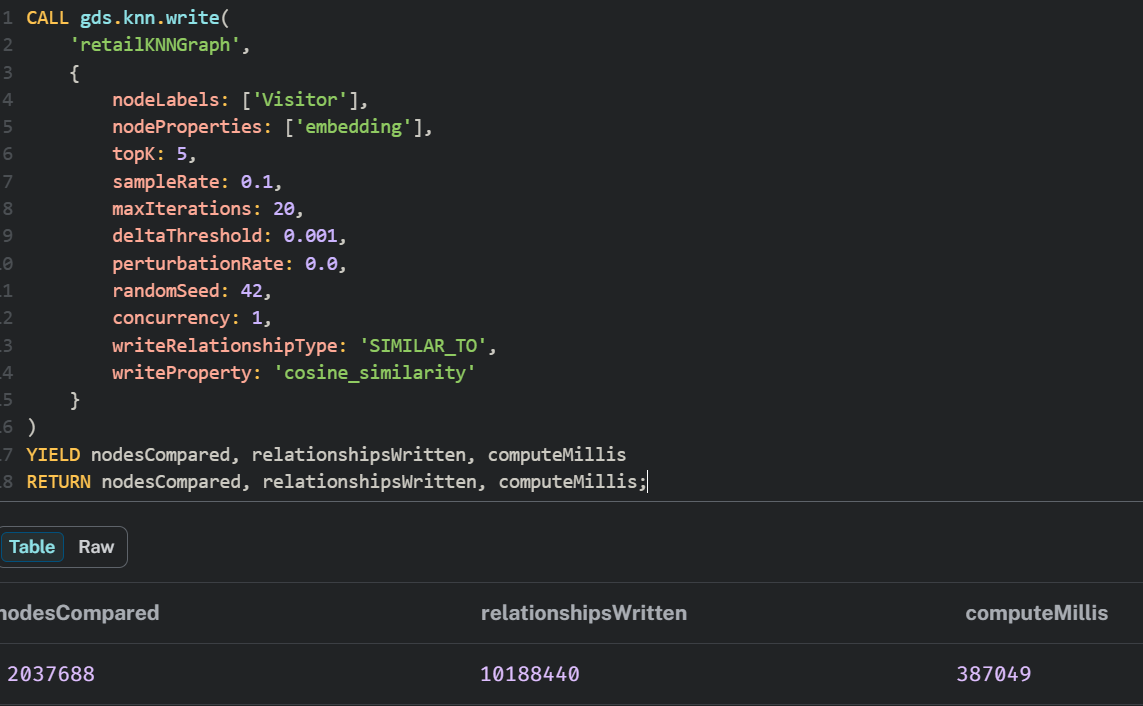

pendekatan KNN dilakukan dengan memproyeksikan graf yang berisi node Visitor dan Item beserta relasi interaksinya, kemudian menggunakan representasi numerik (embedding) pada node sebagai dasar perhitungan kemiripan. Algoritma gds.knn.write membandingkan embedding antarnode menggunakan cosine similarity dan membentuk relasi SIMILAR_TO dengan properti cosine_similarity untuk menyimpan nilai kemiripan antarpengguna. Selanjutnya, relasi tersebut diurutkan berdasarkan nilai kemiripan tertinggi untuk memperoleh tetangga terdekat setiap pengguna.

**Memeriksa apakah relasi KNN sudah tersimpan**

In [71]:
with driver.session() as session:
    result = session.run("""
        MATCH (v:Visitor)-[r:SIMILAR_TO]->(n:Visitor)
        RETURN
            count(r) AS jumlah_relasi_similarity,
            count(DISTINCT v) AS jumlah_visitor_sumber,
            count(DISTINCT n) AS jumlah_visitor_tetangga
    """)

    display(pd.DataFrame([record.data() for record in result]))

,jumlah_relasi_similarity,jumlah_visitor_sumber,jumlah_visitor_tetangga
0,10188445,2037688,1936325


**Menampilkan 10 relasi similarity tertinggi**

In [72]:
query = """
MATCH (v:Visitor)-[r:SIMILAR_TO]->(n:Visitor)
RETURN
    v.visitorId AS visitor_sumber,
    n.visitorId AS visitor_tetangga,
    r.cosine_similarity AS similarity
ORDER BY similarity DESC
LIMIT 10
"""

with driver.session() as session:
    result = session.run(query)
    similarity_df = pd.DataFrame(
        [record.data() for record in result]
    )

display(similarity_df)

,visitor_sumber,visitor_tetangga,similarity
0,130920,179437,1.0
1,317979,179437,1.0
2,613696,179437,1.0
3,495063,784669,1.0
4,1347001,339335,1.0
5,400300,1213673,1.0
6,1048155,179437,1.0
7,1106941,179437,1.0
8,1280826,1213673,1.0
9,1078046,179437,1.0


Nilai cosine similarity sebesar 1,0 menunjukkan bahwa vektor representasi visitor_sumber dan visitor_tetangga memiliki arah yang sama, sehingga dianggap identik dari segi pola fitur yang dibandingkan. Dalam pendekatan KNN menggunakan Neo4j Graph Data Science (GDS), kondisi ini dapat terjadi ketika kedua pengguna memiliki pola interaksi atau nilai embedding yang sangat serupa, meskipun jumlah interaksinya belum tentu sama. Namun, jika banyak pasangan pengguna memperoleh nilai similarity 1,0, hasil tersebut perlu diperiksa lebih lanjut karena dapat disebabkan oleh vektor yang identik, embedding yang kurang bervariasi, atau konfigurasi fitur dan algoritma KNN yang digunakan. Oleh karena itu, nilai 1,0 tidak selalu berarti kedua pengguna memiliki riwayat interaksi yang sepenuhnya sama, melainkan bahwa representasi vektor mereka memiliki kemiripan arah maksimal berdasarkan perhitungan cosine similarity.

**Memeriksa lima tetangga terdekat visitor acuan**

In [74]:
user_acuan = 1150086

query = """
MATCH (u:Visitor {visitorId: $user_id})
      -[r:SIMILAR_TO]->(n:Visitor)
RETURN
    u.visitorId AS visitor_acuan,
    n.visitorId AS visitor_tetangga,
    r.cosine_similarity AS similarity
ORDER BY similarity DESC
LIMIT 5
"""

with driver.session() as session:
    result = session.run(query, user_id=user_acuan)
    tetangga_df = pd.DataFrame(
        [record.data() for record in result]
    )

display(tetangga_df)

,visitor_acuan,visitor_tetangga,similarity
0,1150086,740249,0.841655
1,1150086,735935,0.824275
2,1150086,18523,0.809986
3,1150086,1059295,0.802683
4,1150086,1200516,0.802629


In [75]:
with driver.session() as session:
    result = session.run("""
        MATCH (v:Visitor)
        OPTIONAL MATCH (v)-[r:SIMILAR_TO]->(n:Visitor)
        WITH v, count(r) AS jumlah_tetangga
        RETURN
            v.visitorId AS visitorId,
            jumlah_tetangga
        ORDER BY jumlah_tetangga DESC
        LIMIT 10
    """)

    display(pd.DataFrame(
        [record.data() for record in result]
    ))

,visitorId,jumlah_tetangga
0,1150086,10
1,111016,5
2,794181,5
3,951259,5
4,972639,5
5,810725,5
6,483717,5
7,824915,5
8,339335,5
9,992329,5


**Menentukan 3 item yang diiklankan untuk k = 5**

In [77]:
query = """
MATCH (u:Visitor {visitorId: $user_id})-[r:SIMILAR_TO]->(v:Visitor)
MATCH (v)-[interaction]->(i:Item)
WHERE NOT EXISTS {
    MATCH (u)-[previous]->(i)
}
WITH
    i,
    max(r.cosine_similarity) AS similarity,
    collect(DISTINCT v.visitorId) AS sumber_user
RETURN
    i.itemId AS item_rekomendasi,
    similarity,
    sumber_user
ORDER BY similarity DESC
LIMIT 5
"""

with driver.session() as session:
    result = session.run(query, user_id=reference_id)
    neo4j_results = [record.data() for record in result]

recommendations = pd.DataFrame(neo4j_results)
display(recommendations)

,item_rekomendasi,similarity,sumber_user
0,36189,0.878354,[1135260]
1,286481,0.849726,[1232476]
2,5290,0.849726,[1232476]
3,239235,0.849726,[1232476]
4,119561,0.828855,[1145197]


**Jawaban No 2b.** (b) Tiga item rekomendasi untuk k = 5: 36189 (0.878354), 286481 (0.849726), dan 5290 (0.849726).

**Evaluasi**

 untuk mengukur keberhasilan rekomendasi pada lima item dengan peringkat tertinggi, digunakan metrik evaluasi sebagai berikut :  
1. Hit@5 : mengukur apakah setidaknya terdapat satu item relevan dalam lima rekomendasi teratas
2. NDCG@5 (Normalized Discounted Cumulative Gain at 5) : mengukur kualitas urutan rekomendasi dengan mempertimbangkan posisi item relevan, sehingga item relevan pada peringkat lebih tinggi memberikan nilai yang lebih besar dibandingkan item pada peringkat lebih rendah.

In [79]:

import numpy as np
import pandas as pd

# ============================================================
# 1. MASUKKAN HASIL REKOMENDASI DARI NEO4J
# ============================================================

# Jika hasil query Neo4j sudah disimpan dalam DataFrame bernama
# recommendations, gunakan DataFrame tersebut.
#
# Contoh jika hasil query disimpan sebagai neo4j_results:
recommendations = pd.DataFrame(neo4j_results)

# # Baca hasil rekomendasi yang benar-benar tersimpan di CSV
# recommendations = pd.read_csv("neo4j_results.csv")

# print("Kolom CSV:", recommendations.columns.tolist())
# print("Jumlah baris CSV:", len(recommendations))
# display(recommendations)

# Sesuaikan nama kolom ID item
if "item_rekomendasi" in recommendations.columns:
    rec_items = recommendations["item_rekomendasi"].tolist()
elif "itemid" in recommendations.columns:
    rec_items = recommendations["itemid"].tolist()
else:
    raise ValueError("Kolom ID item tidak ditemukan di recommendations.")

# Maksimal lima rekomendasi
rec_items = rec_items[:5]

# ============================================================
# 2. MENENTUKAN ITEM RELEVAN DARI DATA TESTING
# ============================================================

# Gunakan data testing periode P2 yang sudah dibuat sebelumnya.
# Ground truth = item yang muncul pada testing, tersedia dalam
# katalog training, dan belum pernah diinteraksikan di training.

user_acuan = 1150086

train_items_user = set(
    p1.loc[
        p1["visitorid"] == user_acuan, "itemid"
    ].unique()
)

test_items_user = set(
    p2.loc[
        p2["visitorid"] == user_acuan, "itemid"
    ].unique()
)

# Hanya item testing yang belum pernah diinteraksikan saat training
relevant_items_user = test_items_user - train_items_user

# ============================================================
# 3. HIT@5
# ============================================================

hits = [
    1 if item in relevant_items_user else 0
    for item in rec_items
]

hit_at_5 = int(any(hits))

# ============================================================
# 4. NDCG@5
# ============================================================

# DCG: item relevan pada ranking tinggi memiliki bobot lebih besar
dcg_at_5 = sum(
    rel / np.log2(rank + 1)
    for rank, rel in enumerate(hits, start=1)
)

# IDCG: urutan ideal jika item relevan ditempatkan di posisi teratas
ideal_relevant_count = min(len(relevant_items_user), 5)

idcg_at_5 = sum(
    1 / np.log2(rank + 1)
    for rank in range(1, ideal_relevant_count + 1)
)

ndcg_at_5 = (
    dcg_at_5 / idcg_at_5
    if idcg_at_5 > 0 else 0.0
)

# ============================================================
# 5. TAMPILKAN HASIL EVALUASI
# ============================================================

print("========== EVALUASI KNN ==========")
print("User acuan              :", user_acuan)
print("Jumlah rekomendasi      :", len(rec_items))
print("Item rekomendasi        :", rec_items)
print("Item relevan testing    :", sorted(relevant_items_user))
print("Relevansi tiap ranking  :", hits)
print("Hit@5                   :", hit_at_5)
print("NDCG@5                  :", round(ndcg_at_5, 6))


========== EVALUASI KNN ==========
User acuan              : 1150086
Jumlah rekomendasi      : 5
Item rekomendasi        : ['36189', '286481', '5290', '239235', '119561']
Item relevan testing    : []
Relevansi tiap ranking  : [0, 0, 0, 0, 0]
Hit@5                   : 0
NDCG@5                  : 0.0


**Jawaban No. 2** Hasil evaluasi KNN menunjukkan bahwa sistem menghasilkan lima rekomendasi item untuk user acuan 1150086, yaitu 36189, 286481, 5290, 239235, dan 119561. Namun, tidak ada item rekomendasi yang termasuk dalam daftar item relevan pada data pengujian (testing), sehingga seluruh nilai relevansi pada lima peringkat adalah 0, dengan nilai Hit@5 = 0 dan NDCG@5 = 0,0. Nilai rendah wajar karena rata-rata user hanya punya 3,84 item, interaksi sangat jarang, dan P2 adalah periode berbeda dari P1; nilai nol pada satu user tidak mewakili kualitas model secara keseluruhan.

In [ ]:
driver.close()